In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Dataset 2 - Edge-IIoTset")
print("Setup successful")

Dataset 2 - Edge-IIoTset
Setup successful


In [2]:
p = "ML-EdgeIIoT-dataset.csv"

df = pd.read_csv(p, nrows=5)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (5, 63)

Columns:
['frame.time', 'ip.src_host', 'ip.dst_host', 'arp.dst.proto_ipv4', 'arp.opcode', 'arp.hw.size', 'arp.src.proto_ipv4', 'icmp.checksum', 'icmp.seq_le', 'icmp.transmit_timestamp', 'icmp.unused', 'http.file_data', 'http.content_length', 'http.request.uri.query', 'http.request.method', 'http.referer', 'http.request.full_uri', 'http.request.version', 'http.response', 'http.tls_port', 'tcp.ack', 'tcp.ack_raw', 'tcp.checksum', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'tcp.options', 'tcp.payload', 'tcp.seq', 'tcp.srcport', 'udp.port', 'udp.stream', 'udp.time_delta', 'dns.qry.name', 'dns.qry.name.len', 'dns.qry.qu', 'dns.qry.type', 'dns.retransmission', 'dns.retransmit_request', 'dns.retransmit_request_in', 'mqtt.conack.flags', 'mqtt.conflag.cleansess', 'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.msg_decoded_as', 'mqtt.msg', 'mqtt.msgtype', 'mqtt.proto_len', 

In [3]:
print(df.head())
print("\nData types:")
print(df.dtypes)

print("\nAttack labels:")
print(df["Attack_label"].value_counts())

print("\nAttack types:")
print(df["Attack_type"].value_counts())

   frame.time    ip.src_host  ip.dst_host  arp.dst.proto_ipv4  arp.opcode  \
0         6.0  192.168.0.152          0.0                 0.0         0.0   
1         6.0  192.168.0.101          0.0                 0.0         0.0   
2         6.0  192.168.0.152          0.0                 0.0         0.0   
3         6.0  192.168.0.101          0.0                 0.0         0.0   
4         6.0  192.168.0.152          0.0                 0.0         0.0   

   arp.hw.size  arp.src.proto_ipv4  icmp.checksum  icmp.seq_le  \
0          0.0                 0.0            0.0          0.0   
1          0.0                 0.0            0.0          0.0   
2          0.0                 0.0            0.0          0.0   
3          0.0                 0.0            0.0          0.0   
4          0.0                 0.0            0.0          0.0   

   icmp.transmit_timestamp  ...  mqtt.proto_len  mqtt.protoname  mqtt.topic  \
0                      0.0  ...             0.0             0

In [4]:
from collections import Counter

p = "ML-EdgeIIoT-dataset.csv"

rows = 0
labels = Counter()
attacks = Counter()

for chunk in pd.read_csv(p, chunksize=50000):
    rows += len(chunk)
    labels.update(chunk["Attack_label"].value_counts().to_dict())
    attacks.update(chunk["Attack_type"].value_counts().to_dict())

print("Total rows:", rows)

print("\nAttack_label:")
for k, v in labels.items():
    print(k, ":", v)

print("\nAttack_type:")
for k, v in attacks.items():
    print(k, ":", v)

C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\1918420611.py:9: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.srcport) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\1918420611.py:9: DtypeWarning: Columns (0: http.request.uri.query, 1: http.referer) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):


Total rows: 157800

Attack_label:
1 : 133499
0 : 24301

Attack_type:
Ransomware : 10925
DDoS_HTTP : 10561
SQL_injection : 10311
Uploading : 10269
DDoS_TCP : 10247
MITM : 1214
Fingerprinting : 1001
Backdoor : 10195
Vulnerability_scanner : 10076
Port_Scanning : 10071
Password : 9989
XSS : 10052
Normal : 24301
DDoS_UDP : 14498
DDoS_ICMP : 14090


C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\1918420611.py:9: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.method, 4: http.referer, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.payload, 9: dns.qry.name.len, 10: mqtt.conack.flags, 11: mqtt.msg, 12: mqtt.protoname, 13: mqtt.topic) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):


In [5]:
print("Total rows:", rows)

print("\nAttack_label:")
print(dict(labels))

print("\nAttack_type:")
for k, v in attacks.most_common():
    print(f"{k}: {v}")

Total rows: 157800

Attack_label:
{1: 133499, 0: 24301}

Attack_type:
Normal: 24301
DDoS_UDP: 14498
DDoS_ICMP: 14090
Ransomware: 10925
DDoS_HTTP: 10561
SQL_injection: 10311
Uploading: 10269
DDoS_TCP: 10247
Backdoor: 10195
Vulnerability_scanner: 10076
Port_Scanning: 10071
XSS: 10052
Password: 9989
MITM: 1214
Fingerprinting: 1001


In [6]:
df_sample = pd.read_csv(p, nrows=10000)

print("Shape:", df_sample.shape)

print("\nMissing values:")
print(df_sample.isnull().sum().sort_values(ascending=False).head(20))

print("\nDuplicate rows:", df_sample.duplicated().sum())

print("\nData types:")
print(df_sample.dtypes.value_counts())

Shape: (10000, 63)

Missing values:
frame.time                 0
ip.src_host                0
ip.dst_host                0
arp.dst.proto_ipv4         0
arp.opcode                 0
arp.hw.size                0
arp.src.proto_ipv4         0
icmp.checksum              0
icmp.seq_le                0
icmp.transmit_timestamp    0
icmp.unused                0
http.file_data             0
http.content_length        0
http.request.uri.query     0
http.request.method        0
http.referer               0
http.request.full_uri      0
http.request.version       0
http.response              0
http.tls_port              0
dtype: int64

Duplicate rows: 814

Data types:
float64    53
str         9
int64       1
Name: count, dtype: int64


In [7]:
str_cols = df_sample.select_dtypes(include=["object", "string"]).columns

print("String columns:")
for col in str_cols:
    print(f"\n{col}")
    print("Unique values:", df_sample[col].nunique())
    print(df_sample[col].value_counts().head(10))

String columns:

frame.time
Unique values: 8788
frame.time
0.0                          873
6.0                          341
 2021 22:14:30.939803000       1
 2021 22:14:30.939896000       1
 2021 22:14:31.371846000       1
 2021 22:14:31.371927000       1
 2021 22:14:31.910480000       1
 2021 22:14:31.910544000       1
 2021 22:14:32.458125000       1
 2021 22:14:35.855090000       1
Name: count, dtype: int64

ip.src_host
Unique values: 7
ip.src_host
192.168.0.128    3956
192.168.0.170    3886
0                1770
192.168.0.101     155
192.168.0.152     120
0.0.0.0           111
192.168.0.1         2
Name: count, dtype: int64

ip.dst_host
Unique values: 8
ip.dst_host
192.168.0.128    3884
192.168.0.170    3843
0.0              1214
0                 897
224.0.0.1          53
224.0.0.252        53
224.0.0.251        53
192.168.0.101       3
Name: count, dtype: int64

arp.dst.proto_ipv4
Unique values: 6
arp.dst.proto_ipv4
0                8331
0.0              1214
192.168.0.128     2

In [8]:
# Check unique values and data types using chunks

info = {}

for chunk in pd.read_csv(p, chunksize=50000):
    for col in chunk.columns:
        if col not in info:
            info[col] = {
                "dtype": str(chunk[col].dtype),
                "unique": set()
            }

        # Keep unique values only for manageable columns
        if len(info[col]["unique"]) <= 1000:
            vals = chunk[col].dropna().astype(str).unique()
            info[col]["unique"].update(vals[:1001])

print("Column summary:\n")

for col in df_sample.columns:
    print(
        f"{col:35} "
        f"dtype={info[col]['dtype']:10} "
        f"unique_seen={len(info[col]['unique'])}"
    )

C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\2266741216.py:5: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.srcport) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\2266741216.py:5: DtypeWarning: Columns (0: http.request.uri.query, 1: http.referer) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\2266741216.py:5: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.method, 4: http.referer, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.payload, 9: dns.qry.name.len, 10: mqtt.conack.flags, 11: mqtt.m

Column summary:

frame.time                          dtype=str        unique_seen=1001
ip.src_host                         dtype=str        unique_seen=1001
ip.dst_host                         dtype=str        unique_seen=1001
arp.dst.proto_ipv4                  dtype=object     unique_seen=8
arp.opcode                          dtype=float64    unique_seen=3
arp.hw.size                         dtype=float64    unique_seen=2
arp.src.proto_ipv4                  dtype=object     unique_seen=8
icmp.checksum                       dtype=float64    unique_seen=1565
icmp.seq_le                         dtype=float64    unique_seen=1002
icmp.transmit_timestamp             dtype=float64    unique_seen=84
icmp.unused                         dtype=float64    unique_seen=1
http.file_data                      dtype=object     unique_seen=496
http.content_length                 dtype=float64    unique_seen=33
http.request.uri.query              dtype=object     unique_seen=1665
http.request.method    

In [9]:
# Find columns with only one unique value across the full dataset

unique_counts = {}

for chunk in pd.read_csv(p, chunksize=50000):
    for col in chunk.columns:
        if col not in unique_counts:
            unique_counts[col] = set()

        if len(unique_counts[col]) <= 1:
            vals = chunk[col].dropna().astype(str).unique()
            unique_counts[col].update(vals)

constant_cols = [
    col for col, vals in unique_counts.items()
    if len(vals) == 1
]

print("Constant columns:")
for col in constant_cols:
    print(col)

print("\nNumber of constant columns:", len(constant_cols))

C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3689364233.py:5: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.srcport) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3689364233.py:5: DtypeWarning: Columns (0: http.request.uri.query, 1: http.referer) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3689364233.py:5: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.method, 4: http.referer, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.payload, 9: dns.qry.name.len, 10: mqtt.conack.flags, 11: mqtt.m

Constant columns:
icmp.unused
http.tls_port
dns.qry.type
dns.retransmit_request_in
mqtt.msg_decoded_as
mbtcp.len
mbtcp.trans_id
mbtcp.unit_id

Number of constant columns: 8


In [10]:
p = "ML-EdgeIIoT-dataset.csv"

In [11]:
unique_counts = {}

for chunk in pd.read_csv(p, chunksize=50000):
    for col in chunk.columns:
        if col not in unique_counts:
            unique_counts[col] = set()

        if len(unique_counts[col]) <= 1:
            vals = chunk[col].dropna().astype(str).unique()
            unique_counts[col].update(vals)

constant_cols = [
    col for col, vals in unique_counts.items()
    if len(vals) == 1
]

print("Constant columns:")
for col in constant_cols:
    print(col)

print("\nNumber of constant columns:", len(constant_cols))

C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3687771454.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.srcport) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3687771454.py:3: DtypeWarning: Columns (0: http.request.uri.query, 1: http.referer) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3687771454.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.method, 4: http.referer, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.payload, 9: dns.qry.name.len, 10: mqtt.conack.flags, 11: mqtt.m

Constant columns:
icmp.unused
http.tls_port
dns.qry.type
dns.retransmit_request_in
mqtt.msg_decoded_as
mbtcp.len
mbtcp.trans_id
mbtcp.unit_id

Number of constant columns: 8


In [12]:
unique_counts = {}

for chunk in pd.read_csv(p, chunksize=50000):
    for col in chunk.columns:
        if col not in unique_counts:
            unique_counts[col] = set()

        if len(unique_counts[col]) < 5000:
            vals = chunk[col].dropna().astype(str).unique()
            unique_counts[col].update(vals)

print("Column cardinality:")
for col in p and df_sample.columns:
    print(f"{col:35} {len(unique_counts[col])}")

C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\2381846548.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.srcport) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\2381846548.py:3: DtypeWarning: Columns (0: http.request.uri.query, 1: http.referer) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\2381846548.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.method, 4: http.referer, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.payload, 9: dns.qry.name.len, 10: mqtt.conack.flags, 11: mqtt.m

Column cardinality:
frame.time                          48787
ip.src_host                         6021
ip.dst_host                         6900
arp.dst.proto_ipv4                  8
arp.opcode                          3
arp.hw.size                         2
arp.src.proto_ipv4                  8
icmp.checksum                       6532
icmp.seq_le                         7250
icmp.transmit_timestamp             84
icmp.unused                         1
http.file_data                      496
http.content_length                 33
http.request.uri.query              1665
http.request.method                 6
http.referer                        4
http.request.full_uri               4073
http.request.version                8
http.response                       2
http.tls_port                       1
tcp.ack                             8600
tcp.ack_raw                         31758
tcp.checksum                        33401
tcp.connection.fin                  2
tcp.connection.rst             

In [13]:
unique_counts = {}

for chunk in pd.read_csv(p, chunksize=50000):
    for col in chunk.columns:
        if col not in unique_counts:
            unique_counts[col] = set()

        if len(unique_counts[col]) < 5000:
            vals = chunk[col].dropna().astype(str).unique()
            unique_counts[col].update(vals)

print("Column cardinality:")
for col in df_sample.columns:
    print(f"{col:35} {len(unique_counts[col])}")

C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\29330083.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.srcport) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\29330083.py:3: DtypeWarning: Columns (0: http.request.uri.query, 1: http.referer) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\29330083.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.method, 4: http.referer, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.payload, 9: dns.qry.name.len, 10: mqtt.conack.flags, 11: mqtt.msg, 12

Column cardinality:
frame.time                          48787
ip.src_host                         6021
ip.dst_host                         6900
arp.dst.proto_ipv4                  8
arp.opcode                          3
arp.hw.size                         2
arp.src.proto_ipv4                  8
icmp.checksum                       6532
icmp.seq_le                         7250
icmp.transmit_timestamp             84
icmp.unused                         1
http.file_data                      496
http.content_length                 33
http.request.uri.query              1665
http.request.method                 6
http.referer                        4
http.request.full_uri               4073
http.request.version                8
http.response                       2
http.tls_port                       1
tcp.ack                             8600
tcp.ack_raw                         31758
tcp.checksum                        33401
tcp.connection.fin                  2
tcp.connection.rst             

In [14]:
print("Attack label distribution:")
print(df_sample["Attack_label"].value_counts())

print("\nAttack label percentage:")
print(
    df_sample["Attack_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Attack label distribution:
Attack_label
1    10000
Name: count, dtype: int64

Attack label percentage:
Attack_label
1    100.0
Name: proportion, dtype: float64


In [15]:
missing = {}

for chunk in pd.read_csv(p, chunksize=50000):
    for col in chunk.columns:
        missing[col] = missing.get(col, 0) + chunk[col].isna().sum()

print("Columns containing missing values:")

found = False

for col, count in missing.items():
    if count > 0:
        print(f"{col}: {count}")
        found = True

if not found:
    print("No missing values found.")

C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\107429021.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.srcport) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\107429021.py:3: DtypeWarning: Columns (0: http.request.uri.query, 1: http.referer) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):


Columns containing missing values:
No missing values found.


C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\107429021.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.method, 4: http.referer, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.payload, 9: dns.qry.name.len, 10: mqtt.conack.flags, 11: mqtt.msg, 12: mqtt.protoname, 13: mqtt.topic) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):


In [16]:
duplicate_count = 0

for chunk in pd.read_csv(p, chunksize=50000):
    duplicate_count += chunk.duplicated().sum()

print("Duplicate rows found within chunks:", duplicate_count)

C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3799704834.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.srcport) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):
C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3799704834.py:3: DtypeWarning: Columns (0: http.request.uri.query, 1: http.referer) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):


Duplicate rows found within chunks: 814


C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3799704834.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.method, 4: http.referer, 5: http.request.full_uri, 6: http.request.version, 7: tcp.options, 8: tcp.payload, 9: dns.qry.name.len, 10: mqtt.conack.flags, 11: mqtt.msg, 12: mqtt.protoname, 13: mqtt.topic) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, chunksize=50000):


In [17]:
num_cols = df_sample.select_dtypes(include=["number"]).columns

print("Numerical columns:", len(num_cols))
print()

for col in num_cols:
    print(
        f"{col:35} "
        f"min={df_sample[col].min()} "
        f"max={df_sample[col].max()} "
        f"unique={df_sample[col].nunique()}"
    )

Numerical columns: 54

arp.opcode                          min=0.0 max=2.0 unique=3
arp.hw.size                         min=0.0 max=6.0 unique=2
icmp.checksum                       min=0.0 max=65512.0 unique=578
icmp.seq_le                         min=0.0 max=256.0 unique=2
icmp.transmit_timestamp             min=0.0 max=77289023.0 unique=84
icmp.unused                         min=0.0 max=0.0 unique=1
http.file_data                      min=0.0 max=0.0 unique=1
http.content_length                 min=0.0 max=0.0 unique=1
http.request.uri.query              min=0.0 max=0.0 unique=1
http.request.method                 min=0.0 max=0.0 unique=1
http.referer                        min=0.0 max=0.0 unique=1
http.request.full_uri               min=0.0 max=0.0 unique=1
http.request.version                min=0.0 max=0.0 unique=1
http.response                       min=0.0 max=0.0 unique=1
http.tls_port                       min=0.0 max=0.0 unique=1
tcp.ack                             min=0.0 ma

In [18]:
check_cols = [
    "ip.src_host",
    "ip.dst_host",
    "arp.dst.proto_ipv4",
    "arp.src.proto_ipv4",
    "tcp.srcport",
    "tcp.dstport",
    "http.request.method",
    "http.request.version"
]

for col in check_cols:
    if col in df_sample.columns:
        print("\n" + "=" * 60)
        print(col)
        print(
            pd.crosstab(
                df_sample[col],
                df_sample["Attack_label"],
                normalize="index"
            ).head(15)
        )


ip.src_host
Attack_label     1
ip.src_host       
0              1.0
0.0.0.0        1.0
192.168.0.1    1.0
192.168.0.101  1.0
192.168.0.128  1.0
192.168.0.152  1.0
192.168.0.170  1.0

ip.dst_host
Attack_label     1
ip.dst_host       
0              1.0
0.0            1.0
192.168.0.101  1.0
192.168.0.128  1.0
192.168.0.170  1.0
224.0.0.1      1.0
224.0.0.251    1.0
224.0.0.252    1.0

arp.dst.proto_ipv4
Attack_label          1
arp.dst.proto_ipv4     
0                   1.0
0.0                 1.0
192.168.0.1         1.0
192.168.0.101       1.0
192.168.0.128       1.0
192.168.0.170       1.0

arp.src.proto_ipv4
Attack_label          1
arp.src.proto_ipv4     
0                   1.0
0.0                 1.0
192.168.0.1         1.0
192.168.0.101       1.0
192.168.0.128       1.0
192.168.0.170       1.0

tcp.srcport
Attack_label    1
tcp.srcport      
0             1.0
0.0           1.0
10019.0       1.0
11064.0       1.0
11782.0       1.0
1226.0        1.0
12261.0       1.0
12924.0       

In [19]:
df = pd.read_csv(p, low_memory=False)

print("Shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate percentage:",
      round(df.duplicated().mean() * 100, 2), "%")

Shape: (157800, 63)

Duplicate rows: 814

Duplicate percentage: 0.52 %


In [20]:
card = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "unique": [df[c].nunique(dropna=False) for c in df.columns]
})

print(card.to_string(index=False))

                   column   dtype  unique
               frame.time     str  155186
              ip.src_host     str   19090
              ip.dst_host     str    8084
       arp.dst.proto_ipv4     str       8
               arp.opcode float64       3
              arp.hw.size float64       2
       arp.src.proto_ipv4     str       8
            icmp.checksum float64   13187
              icmp.seq_le float64   13824
  icmp.transmit_timestamp float64      84
              icmp.unused float64       1
           http.file_data     str     496
      http.content_length float64      33
   http.request.uri.query     str    1665
      http.request.method     str       6
             http.referer     str       4
    http.request.full_uri     str    4073
     http.request.version     str       8
            http.response float64       2
            http.tls_port float64       1
                  tcp.ack float64   27929
              tcp.ack_raw float64   94716
             tcp.checksum float64 

In [21]:
obj_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("Object/string columns:")
for col in obj_cols:
    print(col)

print("\nNumber of object columns:", len(obj_cols))

Object/string columns:
frame.time
ip.src_host
ip.dst_host
arp.dst.proto_ipv4
arp.src.proto_ipv4
http.file_data
http.request.uri.query
http.request.method
http.referer
http.request.full_uri
http.request.version
tcp.options
tcp.payload
tcp.srcport
dns.qry.name.len
mqtt.conack.flags
mqtt.msg
mqtt.protoname
mqtt.topic
Attack_type

Number of object columns: 20


C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3642098196.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=["object"]).columns.tolist()


In [22]:
print("Attack_label:")
print(df["Attack_label"].value_counts())

print("\nAttack_label percentage:")
print(
    df["Attack_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nAttack_type:")
print(df["Attack_type"].value_counts())

Attack_label:
Attack_label
1    133499
0     24301
Name: count, dtype: int64

Attack_label percentage:
Attack_label
1    84.6
0    15.4
Name: proportion, dtype: float64

Attack_type:
Attack_type
Normal                   24301
DDoS_UDP                 14498
DDoS_ICMP                14090
Ransomware               10925
DDoS_HTTP                10561
SQL_injection            10311
Uploading                10269
DDoS_TCP                 10247
Backdoor                 10195
Vulnerability_scanner    10076
Port_Scanning            10071
XSS                      10052
Password                  9989
MITM                      1214
Fingerprinting            1001
Name: count, dtype: int64


In [23]:
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Original shape:", df.shape)
print("After removing duplicates:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

Original shape: (157800, 63)
After removing duplicates: (156986, 63)
Rows removed: 814


In [24]:
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

print(df_clean.columns.tolist())

['frame.time', 'ip.src_host', 'ip.dst_host', 'arp.dst.proto_ipv4', 'arp.opcode', 'arp.hw.size', 'arp.src.proto_ipv4', 'icmp.checksum', 'icmp.seq_le', 'icmp.transmit_timestamp', 'icmp.unused', 'http.file_data', 'http.content_length', 'http.request.uri.query', 'http.request.method', 'http.referer', 'http.request.full_uri', 'http.request.version', 'http.response', 'http.tls_port', 'tcp.ack', 'tcp.ack_raw', 'tcp.checksum', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'tcp.options', 'tcp.payload', 'tcp.seq', 'tcp.srcport', 'udp.port', 'udp.stream', 'udp.time_delta', 'dns.qry.name', 'dns.qry.name.len', 'dns.qry.qu', 'dns.qry.type', 'dns.retransmission', 'dns.retransmit_request', 'dns.retransmit_request_in', 'mqtt.conack.flags', 'mqtt.conflag.cleansess', 'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.msg_decoded_as', 'mqtt.msg', 'mqtt.msgtype', 'mqtt.proto_len', 'mqtt.protoname', 'mqtt.t

In [25]:
card = pd.DataFrame({
    "column": df_clean.columns,
    "dtype": df_clean.dtypes.astype(str).values,
    "unique": [df_clean[c].nunique(dropna=False) for c in df_clean.columns]
})

print(
    card.sort_values("unique", ascending=False)
         .to_string(index=False)
)

                   column   dtype  unique
               frame.time     str  155186
              tcp.ack_raw float64   94716
              tcp.options     str   73139
             tcp.checksum float64   55513
              tcp.srcport     str   32186
                  tcp.ack float64   27929
              tcp.payload     str   27369
              tcp.dstport float64   23188
              ip.src_host     str   19090
                  tcp.seq float64   18199
               udp.stream float64   14492
              icmp.seq_le float64   13824
            icmp.checksum float64   13187
              ip.dst_host     str    8084
    http.request.full_uri     str    4073
   http.request.uri.query     str    1665
             dns.qry.name float64    1430
                  tcp.len float64     786
           http.file_data     str     496
                 mqtt.msg     str     117
  icmp.transmit_timestamp float64      84
               dns.qry.qu float64      66
           udp.time_delta float64 

In [26]:
num_cols = df_clean.select_dtypes(include="number").columns.tolist()

stats = df_clean[num_cols].describe().T

stats["unique"] = [
    df_clean[c].nunique(dropna=False)
    for c in num_cols
]

print(stats.to_string())

                              count          mean           std  min      25%           50%           75%           max  unique
arp.opcode                 156986.0  1.426879e-02  1.501671e-01  0.0     0.00  0.000000e+00  0.000000e+00  2.000000e+00       3
arp.hw.size                156986.0  6.015823e-02  5.977731e-01  0.0     0.00  0.000000e+00  0.000000e+00  6.000000e+00       2
icmp.checksum              156986.0  3.063093e+03  1.117102e+04  0.0     0.00  0.000000e+00  0.000000e+00  6.553200e+04   13187
icmp.seq_le                156986.0  3.256780e+03  1.143321e+04  0.0     0.00  0.000000e+00  0.000000e+00  6.552400e+04   13824
icmp.transmit_timestamp    156986.0  4.067800e+04  1.768640e+06  0.0     0.00  0.000000e+00  0.000000e+00  7.728902e+07      84
icmp.unused                156986.0  0.000000e+00  0.000000e+00  0.0     0.00  0.000000e+00  0.000000e+00  0.000000e+00       1
http.content_length        156986.0  1.479182e+01  2.302519e+02  0.0     0.00  0.000000e+00  0.000000e+0

In [27]:
cat_cols = [
    c for c in df_clean.columns
    if c not in ["Attack_label", "Attack_type"]
    and (
        df_clean[c].dtype == "object"
        or df_clean[c].nunique() <= 20
    )
]

for col in cat_cols:
    print("\n" + "=" * 70)
    print(col)

    temp = (
        df_clean.groupby(col)["Attack_label"]
        .agg(["count", "mean"])
        .sort_values("count", ascending=False)
        .head(15)
    )

    temp["attack_rate_%"] = (temp["mean"] * 100).round(2)
    print(temp[["count", "attack_rate_%"]])


arp.dst.proto_ipv4
                     count  attack_rate_%
arp.dst.proto_ipv4                       
0                   153610          84.21
192.168.0.128         2052          99.66
192.168.0.170          595         100.00
0.0                    400         100.00
192.168.0.147          223          90.13
192.168.0.1             87          95.40
192.168.0.101           12          83.33
192.168.0.129            7           0.00

arp.opcode
             count  attack_rate_%
arp.opcode                       
0.0         155412          84.39
1.0            908          95.81
2.0            666          99.40

arp.hw.size
              count  attack_rate_%
arp.hw.size                       
0.0          155412          84.39
6.0            1574          97.33

arp.src.proto_ipv4
                     count  attack_rate_%
arp.src.proto_ipv4                       
0                   140514          82.74
0.0                  14898         100.00
192.168.0.128          683          9

In [28]:
drop_cols = [
    "Attack_label",
    "Attack_type",
    "frame.time",
    "ip.src_host",
    "ip.dst_host",
    "tcp.payload",
    "tcp.options",
    "http.file_data",
    "http.request.full_uri",
    "http.request.uri.query",
    
    "icmp.unused",
    "http.tls_port",
    "dns.qry.type",
    "dns.retransmit_request_in",
    "mqtt.msg_decoded_as",
    "mbtcp.len",
    "mbtcp.trans_id",
    "mbtcp.unit_id"
]

X = df_clean.drop(columns=drop_cols)
y = df_clean["Attack_label"]

print("Original columns:", len(df_clean.columns))
print("Dropped columns:", len(drop_cols))
print("Remaining features:", X.shape[1])

print("\nDropped columns:")
for col in drop_cols:
    print("-", col)

print("\nTarget distribution:")
print(y.value_counts())

Original columns: 63
Dropped columns: 18
Remaining features: 45

Dropped columns:
- Attack_label
- Attack_type
- frame.time
- ip.src_host
- ip.dst_host
- tcp.payload
- tcp.options
- http.file_data
- http.request.full_uri
- http.request.uri.query
- icmp.unused
- http.tls_port
- dns.qry.type
- dns.retransmit_request_in
- mqtt.msg_decoded_as
- mbtcp.len
- mbtcp.trans_id
- mbtcp.unit_id

Target distribution:
Attack_label
1    132685
0     24301
Name: count, dtype: int64


In [29]:
print("Remaining object/string columns:")

obj_cols = X.select_dtypes(include=["object", "str"]).columns.tolist()

for col in obj_cols:
    print(col)

print("\nNumber of categorical columns:", len(obj_cols))
print("Number of numerical columns:", X.shape[1] - len(obj_cols))

Remaining object/string columns:
arp.dst.proto_ipv4
arp.src.proto_ipv4
http.request.method
http.referer
http.request.version
tcp.srcport
dns.qry.name.len
mqtt.conack.flags
mqtt.msg
mqtt.protoname
mqtt.topic

Number of categorical columns: 11
Number of numerical columns: 34


In [30]:
high_card = []

for col in X.columns:
    n = X[col].nunique(dropna=False)

    if n > 100:
        high_card.append((col, n))

print("Features with >100 unique values:")

for col, n in sorted(high_card, key=lambda x: x[1], reverse=True):
    print(f"{col:35} {n}")

print("\nNumber of high-cardinality features:", len(high_card))

Features with >100 unique values:
tcp.ack_raw                         94716
tcp.checksum                        55513
tcp.srcport                         32186
tcp.ack                             27929
tcp.dstport                         23188
tcp.seq                             18199
udp.stream                          14492
icmp.seq_le                         13824
icmp.checksum                       13187
dns.qry.name                        1430
tcp.len                             786
mqtt.msg                            117

Number of high-cardinality features: 12


In [31]:
high_card_cols = [
    "tcp.ack_raw",
    "tcp.checksum",
    "tcp.srcport",
    "tcp.ack",
    "tcp.dstport",
    "tcp.seq",
    "udp.stream",
    "icmp.seq_le",
    "icmp.checksum",
    "dns.qry.name",
    "tcp.len",
    "mqtt.msg"
]

for col in high_card_cols:
    print("\n" + "=" * 70)
    print(col)

    print("Unique values:", X[col].nunique())
    print("Data type:", X[col].dtype)

    print("\nMost common values:")
    print(X[col].value_counts(dropna=False).head(10))


tcp.ack_raw
Unique values: 94716
Data type: float64

Most common values:
tcp.ack_raw
0.000000e+00    46341
2.013966e+09     3002
2.213215e+09     2544
1.453307e+09     2082
1.013594e+09     1304
1.679854e+09       15
3.322480e+09       14
3.004337e+09       13
3.903831e+09       13
2.208223e+09       13
Name: count, dtype: int64

tcp.checksum
Unique values: 55513
Data type: float64

Most common values:
tcp.checksum
0.0        33106
51526.0       12
64783.0       12
33678.0       10
53888.0       10
61198.0       10
22207.0       10
7471.0         9
43015.0        9
52241.0        9
Name: count, dtype: int64

tcp.srcport
Unique values: 32186
Data type: str

Most common values:
tcp.srcport
80.0       34437
0.0        19610
1883.0     10075
4321.0      9660
47924.0     3002
5900.0      2844
60210.0     2559
56322.0     2082
3333.0      1989
35306.0     1305
Name: count, dtype: int64

tcp.ack
Unique values: 27929
Data type: float64

Most common values:
tcp.ack
0.0      46341
1.0      3356

In [32]:
print("Uniqueness ratio:\n")

for col in high_card_cols:
    unique = X[col].nunique()
    ratio = unique / len(X)

    print(
        f"{col:30} "
        f"unique={unique:7} "
        f"ratio={ratio:.4f}"
    )

Uniqueness ratio:

tcp.ack_raw                    unique=  94716 ratio=0.6033
tcp.checksum                   unique=  55513 ratio=0.3536
tcp.srcport                    unique=  32186 ratio=0.2050
tcp.ack                        unique=  27929 ratio=0.1779
tcp.dstport                    unique=  23188 ratio=0.1477
tcp.seq                        unique=  18199 ratio=0.1159
udp.stream                     unique=  14492 ratio=0.0923
icmp.seq_le                    unique=  13824 ratio=0.0881
icmp.checksum                  unique=  13187 ratio=0.0840
dns.qry.name                   unique=   1430 ratio=0.0091
tcp.len                        unique=    786 ratio=0.0050
mqtt.msg                       unique=    117 ratio=0.0007


In [33]:
num_cols = X.select_dtypes(include="number").columns.tolist()

rows = []

for col in num_cols:
    normal = X.loc[y == 0, col]
    attack = X.loc[y == 1, col]

    rows.append({
        "feature": col,
        "normal_mean": normal.mean(),
        "attack_mean": attack.mean(),
        "normal_median": normal.median(),
        "attack_median": attack.median()
    })

num_compare = pd.DataFrame(rows)

print(num_compare.to_string(index=False))

                feature  normal_mean  attack_mean  normal_median  attack_median
             arp.opcode 1.892926e-03 1.653540e-02            0.0            0.0
            arp.hw.size 1.036994e-02 6.927686e-02            0.0            0.0
          icmp.checksum 0.000000e+00 3.624092e+03            0.0            0.0
            icmp.seq_le 0.000000e+00 3.853253e+03            0.0            0.0
icmp.transmit_timestamp 0.000000e+00 4.812809e+04            0.0            0.0
    http.content_length 0.000000e+00 1.750092e+01            0.0            0.0
          http.response 0.000000e+00 5.440705e-02            0.0            0.0
                tcp.ack 5.339086e+06 8.417527e+07            6.0            1.0
            tcp.ack_raw 1.794106e+09 1.286872e+09   1860735544.0   1013594299.0
           tcp.checksum 3.250189e+04 2.472680e+04        32399.0        22137.0
     tcp.connection.fin 1.069915e-01 4.955345e-02            0.0            0.0
     tcp.connection.rst 9.958438e-02 9.3

In [34]:
cat_cols = X.select_dtypes(include=["object", "str"]).columns.tolist()

print("Categorical features:\n")

for col in cat_cols:
    print(
        f"{col:30} "
        f"unique={X[col].nunique(dropna=False)}"
    )

Categorical features:

arp.dst.proto_ipv4             unique=8
arp.src.proto_ipv4             unique=8
http.request.method            unique=6
http.referer                   unique=4
http.request.version           unique=8
tcp.srcport                    unique=32186
dns.qry.name.len               unique=8
mqtt.conack.flags              unique=3
mqtt.msg                       unique=117
mqtt.protoname                 unique=3
mqtt.topic                     unique=3


In [35]:
drop_extra = [
    "tcp.ack_raw",
    "tcp.checksum",
    "tcp.seq",
    "udp.stream",
    "icmp.checksum",
    "dns.qry.name",
    "mqtt.msg",
    "tcp.srcport"
]

X2 = X.drop(columns=drop_extra)

print("Features before additional removal:", X.shape[1])
print("Additional features removed:", len(drop_extra))
print("Final candidate features:", X2.shape[1])

print("\nRemoved:")
for col in drop_extra:
    print("-", col)

print("\nRemaining features:")
for i, col in enumerate(X2.columns, 1):
    print(i, col)

Features before additional removal: 45
Additional features removed: 8
Final candidate features: 37

Removed:
- tcp.ack_raw
- tcp.checksum
- tcp.seq
- udp.stream
- icmp.checksum
- dns.qry.name
- mqtt.msg
- tcp.srcport

Remaining features:
1 arp.dst.proto_ipv4
2 arp.opcode
3 arp.hw.size
4 arp.src.proto_ipv4
5 icmp.seq_le
6 icmp.transmit_timestamp
7 http.content_length
8 http.request.method
9 http.referer
10 http.request.version
11 http.response
12 tcp.ack
13 tcp.connection.fin
14 tcp.connection.rst
15 tcp.connection.syn
16 tcp.connection.synack
17 tcp.dstport
18 tcp.flags
19 tcp.flags.ack
20 tcp.len
21 udp.port
22 udp.time_delta
23 dns.qry.name.len
24 dns.qry.qu
25 dns.retransmission
26 dns.retransmit_request
27 mqtt.conack.flags
28 mqtt.conflag.cleansess
29 mqtt.conflags
30 mqtt.hdrflags
31 mqtt.len
32 mqtt.msgtype
33 mqtt.proto_len
34 mqtt.protoname
35 mqtt.topic
36 mqtt.topic_len
37 mqtt.ver


In [36]:
cat_cols = X2.select_dtypes(include=["object", "str"]).columns.tolist()

print("Categorical features:", len(cat_cols))

for col in cat_cols:
    print(f"{col:30} unique={X2[col].nunique(dropna=False)}")

Categorical features: 9
arp.dst.proto_ipv4             unique=8
arp.src.proto_ipv4             unique=8
http.request.method            unique=6
http.referer                   unique=4
http.request.version           unique=8
dns.qry.name.len               unique=8
mqtt.conack.flags              unique=3
mqtt.protoname                 unique=3
mqtt.topic                     unique=3


In [37]:
import numpy as np

num_cols = X2.select_dtypes(include="number").columns

inf_counts = np.isinf(X2[num_cols]).sum()

print("Infinite values by column:")

found = False

for col, count in inf_counts.items():
    if count > 0:
        print(col, count)
        found = True

if not found:
    print("No infinite values found.")

Infinite values by column:
No infinite values found.


In [38]:
print(
    "X2 memory usage:",
    round(X2.memory_usage(deep=True).sum() / (1024**2), 2),
    "MB"
)

print(
    "y memory usage:",
    round(y.memory_usage(deep=True) / (1024**2), 2),
    "MB"
)

X2 memory usage: 102.71 MB
y memory usage: 1.2 MB


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X2,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (109890, 37)
Validation: (23548, 37)
Test: (23548, 37)


In [40]:
print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nVALIDATION")
print(y_val.value_counts())
print(y_val.value_counts(normalize=True).mul(100).round(2))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True).mul(100).round(2))

TRAIN
Attack_label
1    92879
0    17011
Name: count, dtype: int64
Attack_label
1    84.52
0    15.48
Name: proportion, dtype: float64

VALIDATION
Attack_label
1    19903
0     3645
Name: count, dtype: int64
Attack_label
1    84.52
0    15.48
Name: proportion, dtype: float64

TEST
Attack_label
1    19903
0     3645
Name: count, dtype: int64
Attack_label
1    84.52
0    15.48
Name: proportion, dtype: float64


In [41]:
print("Train-Val overlap:", len(set(X_train.index) & set(X_val.index)))
print("Train-Test overlap:", len(set(X_train.index) & set(X_test.index)))
print("Val-Test overlap:", len(set(X_val.index) & set(X_test.index)))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [42]:
cat_cols = X_train.select_dtypes(include=["object", "str"]).columns.tolist()

for col in cat_cols:
    train_vals = set(X_train[col].astype(str).unique())
    val_vals = set(X_val[col].astype(str).unique())
    test_vals = set(X_test[col].astype(str).unique())

    print("\n" + "=" * 60)
    print(col)
    print("Train:", len(train_vals))
    print("Validation:", len(val_vals))
    print("Test:", len(test_vals))
    print("Validation unseen:", len(val_vals - train_vals))
    print("Test unseen:", len(test_vals - train_vals))


arp.dst.proto_ipv4
Train: 8
Validation: 7
Test: 7
Validation unseen: 0
Test unseen: 0

arp.src.proto_ipv4
Train: 6
Validation: 7
Test: 7
Validation unseen: 1
Test unseen: 1

http.request.method
Train: 6
Validation: 5
Test: 5
Validation unseen: 0
Test unseen: 0

http.referer
Train: 4
Validation: 4
Test: 4
Validation unseen: 0
Test unseen: 0

http.request.version
Train: 8
Validation: 4
Test: 5
Validation unseen: 0
Test unseen: 0

dns.qry.name.len
Train: 8
Validation: 6
Test: 7
Validation unseen: 0
Test unseen: 0

mqtt.conack.flags
Train: 3
Validation: 3
Test: 3
Validation unseen: 0
Test unseen: 0

mqtt.protoname
Train: 3
Validation: 3
Test: 3
Validation unseen: 0
Test unseen: 0

mqtt.topic
Train: 3
Validation: 3
Test: 3
Validation unseen: 0
Test unseen: 0


In [43]:
print("Final split summary")
print("-" * 40)

print(f"Total:      {len(X2):,}")
print(f"Train:      {len(X_train):,} ({len(X_train)/len(X2)*100:.1f}%)")
print(f"Validation: {len(X_val):,} ({len(X_val)/len(X2)*100:.1f}%)")
print(f"Test:       {len(X_test):,} ({len(X_test)/len(X2)*100:.1f}%)")

Final split summary
----------------------------------------
Total:      156,986
Train:      109,890 (70.0%)
Validation: 23,548 (15.0%)
Test:       23,548 (15.0%)


In [44]:
cat_cols = X_train.select_dtypes(include=["object", "str"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

print("Categorical columns:", len(cat_cols))
print(cat_cols)

print("\nNumerical columns:", len(num_cols))
print(num_cols)

Categorical columns: 9
['arp.dst.proto_ipv4', 'arp.src.proto_ipv4', 'http.request.method', 'http.referer', 'http.request.version', 'dns.qry.name.len', 'mqtt.conack.flags', 'mqtt.protoname', 'mqtt.topic']

Numerical columns: 28
['arp.opcode', 'arp.hw.size', 'icmp.seq_le', 'icmp.transmit_timestamp', 'http.content_length', 'http.response', 'tcp.ack', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'udp.port', 'udp.time_delta', 'dns.qry.qu', 'dns.retransmission', 'dns.retransmit_request', 'mqtt.conflag.cleansess', 'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.msgtype', 'mqtt.proto_len', 'mqtt.topic_len', 'mqtt.ver']


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), cat_cols),
        ("num", "passthrough", num_cols)
    ]
)

print("Preprocessor created.")

Preprocessor created.


In [46]:
X_train_enc = preprocessor.fit_transform(X_train)

X_val_enc = preprocessor.transform(X_val)

X_test_enc = preprocessor.transform(X_test)

print("Train encoded:", X_train_enc.shape)
print("Validation encoded:", X_val_enc.shape)
print("Test encoded:", X_test_enc.shape)

Train encoded: (109890, 77)
Validation encoded: (23548, 77)
Test encoded: (23548, 77)


In [47]:
feature_names = preprocessor.get_feature_names_out()

print("Encoded feature count:", len(feature_names))

print("\nFirst 30 encoded features:")
for i, name in enumerate(feature_names[:30], 1):
    print(i, name)

Encoded feature count: 77

First 30 encoded features:
1 cat__arp.dst.proto_ipv4_0
2 cat__arp.dst.proto_ipv4_0.0
3 cat__arp.dst.proto_ipv4_192.168.0.1
4 cat__arp.dst.proto_ipv4_192.168.0.101
5 cat__arp.dst.proto_ipv4_192.168.0.128
6 cat__arp.dst.proto_ipv4_192.168.0.129
7 cat__arp.dst.proto_ipv4_192.168.0.147
8 cat__arp.dst.proto_ipv4_192.168.0.170
9 cat__arp.src.proto_ipv4_0
10 cat__arp.src.proto_ipv4_0.0
11 cat__arp.src.proto_ipv4_192.168.0.1
12 cat__arp.src.proto_ipv4_192.168.0.101
13 cat__arp.src.proto_ipv4_192.168.0.128
14 cat__arp.src.proto_ipv4_192.168.0.170
15 cat__http.request.method_0
16 cat__http.request.method_0.0
17 cat__http.request.method_GET
18 cat__http.request.method_OPTIONS
19 cat__http.request.method_POST
20 cat__http.request.method_TRACE
21 cat__http.referer_() { _; } >_[$($())] { echo 93e4r0-CVE-2014-6278: true; echo;echo; }
22 cat__http.referer_0
23 cat__http.referer_0.0
24 cat__http.referer_127.0.0.1
25 cat__http.request.version_-a HTTP/1.1
26 cat__http.request.v

In [48]:
print("Train NaN:", np.isnan(X_train_enc).sum())
print("Validation NaN:", np.isnan(X_val_enc).sum())
print("Test NaN:", np.isnan(X_test_enc).sum())

print("\nTrain infinite:", np.isinf(X_train_enc).sum())
print("Validation infinite:", np.isinf(X_val_enc).sum())
print("Test infinite:", np.isinf(X_test_enc).sum())

Train NaN: 0
Validation NaN: 0
Test NaN: 0

Train infinite: 0
Validation infinite: 0
Test infinite: 0


In [49]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model.fit(X_train_enc, y_train)

print("Baseline XGBoost trained.")

Baseline XGBoost trained.


In [50]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_val_pred = model.predict(X_val_enc)
y_val_prob = model.predict_proba(X_val_enc)[:, 1]

acc = accuracy_score(y_val, y_val_pred)
prec = precision_score(y_val, y_val_pred)
rec = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
roc = roc_auc_score(y_val, y_val_prob)

print("Validation Results")
print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc, 4))

Validation Results
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0


In [51]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

Confusion Matrix:
[[ 3645     0]
 [    0 19903]]

TN: 3645
FP: 0
FN: 0
TP: 19903


In [52]:
importance = model.feature_importances_

imp = sorted(
    zip(feature_names, importance),
    key=lambda x: x[1],
    reverse=True
)

print("Top 20 features:")
for i, (name, value) in enumerate(imp[:20], 1):
    print(i, name, round(value, 6))

Top 20 features:
1 cat__mqtt.conack.flags_0.0 0.565662
2 cat__mqtt.protoname_0.0 0.26559
3 cat__mqtt.topic_0.0 0.168749
4 cat__arp.dst.proto_ipv4_0 0.0
5 cat__arp.dst.proto_ipv4_0.0 0.0
6 cat__arp.dst.proto_ipv4_192.168.0.1 0.0
7 cat__arp.dst.proto_ipv4_192.168.0.101 0.0
8 cat__arp.dst.proto_ipv4_192.168.0.128 0.0
9 cat__arp.dst.proto_ipv4_192.168.0.129 0.0
10 cat__arp.dst.proto_ipv4_192.168.0.147 0.0
11 cat__arp.dst.proto_ipv4_192.168.0.170 0.0
12 cat__arp.src.proto_ipv4_0 0.0
13 cat__arp.src.proto_ipv4_0.0 0.0
14 cat__arp.src.proto_ipv4_192.168.0.1 0.0
15 cat__arp.src.proto_ipv4_192.168.0.101 0.0
16 cat__arp.src.proto_ipv4_192.168.0.128 0.0
17 cat__arp.src.proto_ipv4_192.168.0.170 0.0
18 cat__http.request.method_0 0.0
19 cat__http.request.method_0.0 0.0
20 cat__http.request.method_GET 0.0


In [53]:
print("Features with non-zero importance:")

count = 0

for name, value in imp:
    if value > 0:
        print(name, round(value, 6))
        count += 1

print("\nTotal non-zero features:", count)

Features with non-zero importance:
cat__mqtt.conack.flags_0.0 0.565662
cat__mqtt.protoname_0.0 0.26559
cat__mqtt.topic_0.0 0.168749

Total non-zero features: 3


In [54]:
cols = [
    "mqtt.conack.flags",
    "mqtt.protoname",
    "mqtt.topic"
]

for c in cols:
    print("\n" + "=" * 60)
    print(c)
    print("=" * 60)
    print(pd.crosstab(df_clean[c], df_clean["Attack_label"], normalize="index").round(4))


mqtt.conack.flags
Attack_label         0    1
mqtt.conack.flags          
0                  1.0  0.0
0.0                0.0  1.0
0x00000000         1.0  0.0

mqtt.protoname
Attack_label      0    1
mqtt.protoname          
0               1.0  0.0
0.0             0.0  1.0
MQTT            1.0  0.0

mqtt.topic
Attack_label                0    1
mqtt.topic                        
0                         1.0  0.0
0.0                       0.0  1.0
Temperature_and_Humidity  1.0  0.0


In [55]:
for c in cols:
    print("\n", c)
    print(df_clean[c].value_counts(dropna=False).head(20))


 mqtt.conack.flags
mqtt.conack.flags
0.0           132685
0              23012
0x00000000      1289
Name: count, dtype: int64

 mqtt.protoname
mqtt.protoname
0.0     132685
0        23051
MQTT      1250
Name: count, dtype: int64

 mqtt.topic
mqtt.topic
0.0                         132685
0                            23055
Temperature_and_Humidity      1246
Name: count, dtype: int64


In [56]:
leak_cols = [
    "mqtt.conack.flags",
    "mqtt.protoname",
    "mqtt.topic"
]

X3 = X2.drop(columns=leak_cols)

print("Original features:", X2.shape[1])
print("Removed features:", len(leak_cols))
print("Remaining features:", X3.shape[1])

Original features: 37
Removed features: 3
Remaining features: 34


In [57]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X3,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nClass distribution:")
print("Train:", y_train.value_counts().to_dict())
print("Validation:", y_val.value_counts().to_dict())
print("Test:", y_test.value_counts().to_dict())

Train: (109890, 34)
Validation: (23548, 34)
Test: (23548, 34)

Class distribution:
Train: {1: 92879, 0: 17011}
Validation: {1: 19903, 0: 3645}
Test: {1: 19903, 0: 3645}


In [58]:
cat_cols = X_train.select_dtypes(include=["object", "str"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols)
    ]
)

X_train_enc = preprocessor.fit_transform(X_train)
X_val_enc = preprocessor.transform(X_val)
X_test_enc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Categorical:", len(cat_cols))
print("Numerical:", len(num_cols))
print("Encoded train:", X_train_enc.shape)
print("Encoded validation:", X_val_enc.shape)
print("Encoded test:", X_test_enc.shape)
print("Encoded features:", len(feature_names))

Categorical: 6
Numerical: 28
Encoded train: (109890, 68)
Encoded validation: (23548, 68)
Encoded test: (23548, 68)
Encoded features: 68


In [59]:
model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model.fit(X_train_enc, y_train)

print("Baseline XGBoost trained.")

Baseline XGBoost trained.


In [60]:
y_val_pred = model.predict(X_val_enc)
y_val_prob = model.predict_proba(X_val_enc)[:, 1]

acc = accuracy_score(y_val, y_val_pred)
prec = precision_score(y_val, y_val_pred)
rec = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
roc = roc_auc_score(y_val, y_val_prob)

print("Validation Results")
print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc, 4))

Validation Results
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0


In [61]:
cm = confusion_matrix(y_val, y_val_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

Confusion Matrix:
[[ 3645     0]
 [    0 19903]]

TN: 3645
FP: 0
FN: 0
TP: 19903


In [62]:
importance = model.feature_importances_

imp = sorted(
    zip(feature_names, importance),
    key=lambda x: x[1],
    reverse=True
)

print("Top 25 features:")

for i, (name, value) in enumerate(imp[:25], 1):
    print(i, name, round(value, 6))

Top 25 features:
1 cat__http.request.method_0.0 0.58658
2 cat__dns.qry.name.len_0 0.335131
3 cat__dns.qry.name.len_0.0 0.031134
4 num__tcp.dstport 0.016956
5 num__tcp.ack 0.016416
6 num__dns.retransmission 0.005757
7 num__tcp.connection.rst 0.002556
8 num__udp.time_delta 0.001142
9 cat__arp.dst.proto_ipv4_192.168.0.147 0.000866
10 num__udp.port 0.000826
11 cat__arp.dst.proto_ipv4_0.0 0.000713
12 cat__http.request.method_0 0.000505
13 cat__arp.src.proto_ipv4_0.0 0.0004
14 cat__http.request.version_0 0.000345
15 num__mqtt.hdrflags 0.000178
16 cat__http.request.version_0.0 0.000123
17 cat__arp.dst.proto_ipv4_0 0.000123
18 cat__arp.src.proto_ipv4_0 0.000122
19 num__dns.qry.qu 8.9e-05
20 num__tcp.len 2.8e-05
21 num__tcp.flags 8e-06
22 cat__arp.dst.proto_ipv4_192.168.0.1 0.0
23 cat__arp.dst.proto_ipv4_192.168.0.101 0.0
24 cat__arp.dst.proto_ipv4_192.168.0.128 0.0
25 cat__arp.dst.proto_ipv4_192.168.0.129 0.0


In [63]:
print("Non-zero importance features:")

count = 0

for name, value in imp:
    if value > 0:
        print(name, round(value, 6))
        count += 1

print("\nTotal non-zero features:", count)

Non-zero importance features:
cat__http.request.method_0.0 0.58658
cat__dns.qry.name.len_0 0.335131
cat__dns.qry.name.len_0.0 0.031134
num__tcp.dstport 0.016956
num__tcp.ack 0.016416
num__dns.retransmission 0.005757
num__tcp.connection.rst 0.002556
num__udp.time_delta 0.001142
cat__arp.dst.proto_ipv4_192.168.0.147 0.000866
num__udp.port 0.000826
cat__arp.dst.proto_ipv4_0.0 0.000713
cat__http.request.method_0 0.000505
cat__arp.src.proto_ipv4_0.0 0.0004
cat__http.request.version_0 0.000345
num__mqtt.hdrflags 0.000178
cat__http.request.version_0.0 0.000123
cat__arp.dst.proto_ipv4_0 0.000123
cat__arp.src.proto_ipv4_0 0.000122
num__dns.qry.qu 8.9e-05
num__tcp.len 2.8e-05
num__tcp.flags 8e-06

Total non-zero features: 21


In [64]:
top_features = [name for name, value in imp[:10]]

print("Top encoded features:")
for f in top_features:
    print(f)

Top encoded features:
cat__http.request.method_0.0
cat__dns.qry.name.len_0
cat__dns.qry.name.len_0.0
num__tcp.dstport
num__tcp.ack
num__dns.retransmission
num__tcp.connection.rst
num__udp.time_delta
cat__arp.dst.proto_ipv4_192.168.0.147
num__udp.port


In [65]:
cols = [
    "http.request.method",
    "dns.qry.name.len"
]

for c in cols:
    print("\n" + "=" * 60)
    print(c)
    print("=" * 60)

    print(
        pd.crosstab(
            df_clean[c],
            df_clean["Attack_label"],
            normalize="index"
        ).round(4)
    )


http.request.method
Attack_label              0       1
http.request.method                
0                    0.0000  1.0000
0.0                  0.2539  0.7461
GET                  0.0000  1.0000
OPTIONS              0.0000  1.0000
POST                 0.0000  1.0000
TRACE                0.0000  1.0000

dns.qry.name.len
Attack_label              0    1
dns.qry.name.len                
0                       1.0  0.0
0.0                     0.0  1.0
0.debian.pool.ntp.org   1.0  0.0
1.0                     0.0  1.0
1.debian.pool.ntp.org   1.0  0.0
2.debian.pool.ntp.org   1.0  0.0
3.debian.pool.ntp.org   1.0  0.0
_googlecast._tcp.local  1.0  0.0


In [66]:
for c in cols:
    print("\n" + "=" * 60)
    print(c)
    print("=" * 60)

    print(df_clean[c].value_counts(dropna=False))


http.request.method
http.request.method
0.0        95728
0          54062
GET         6676
POST         267
TRACE        252
OPTIONS        1
Name: count, dtype: int64

dns.qry.name.len
dns.qry.name.len
0.0                       132458
0                          24272
1.0                          227
1.debian.pool.ntp.org         10
0.debian.pool.ntp.org          8
3.debian.pool.ntp.org          7
2.debian.pool.ntp.org          3
_googlecast._tcp.local         1
Name: count, dtype: int64


In [67]:
for c in cols:
    print("\n" + "=" * 60)
    print(c)
    print("=" * 60)

    print(
        pd.crosstab(
            df_clean[c],
            df_clean["Attack_type"]
        )
    )


http.request.method
Attack_type          Backdoor  DDoS_HTTP  DDoS_ICMP  DDoS_TCP  DDoS_UDP  Fingerprinting  MITM  Normal  Password  Port_Scanning  Ransomware  SQL_injection  Uploading  Vulnerability_scanner   XSS
http.request.method                                                                                                                                                                              
0                           0      10561          0         0         0               0     0       0      9313              0           0           9489       9749                   5764  9186
0.0                     10195          0      14090     10247     14498            1001   400   24301         0          10071       10925              0          0                      0     0
GET                         0          0          0         0         0               0     0       0       434              0           0            822        520                   4286   614
OPTIONS  

In [68]:
leak_cols = [
    "mqtt.conack.flags",
    "mqtt.protoname",
    "mqtt.topic",
    "http.request.method",
    "dns.qry.name.len"
]

X4 = X2.drop(columns=leak_cols)

print("Original features:", X2.shape[1])
print("Removed features:", len(leak_cols))
print("Remaining features:", X4.shape[1])

Original features: 37
Removed features: 5
Remaining features: 32


In [69]:
cat_cols4 = X4.select_dtypes(include=["object", "str"]).columns.tolist()

print("Remaining categorical features:")
for c in cat_cols4:
    print("-", c)

Remaining categorical features:
- arp.dst.proto_ipv4
- arp.src.proto_ipv4
- http.referer
- http.request.version


In [70]:
for c in cat_cols4:
    tab = pd.crosstab(
        X4[c],
        y,
        normalize="index"
    )

    max_purity = tab.max(axis=1).max()

    print(
        f"{c:30s} "
        f"unique={X4[c].nunique(dropna=False):4d} "
        f"max_class_purity={max_purity:.4f}"
    )

arp.dst.proto_ipv4             unique=   8 max_class_purity=1.0000


arp.src.proto_ipv4             unique=   8 max_class_purity=1.0000
http.referer                   unique=   4 max_class_purity=1.0000
http.request.version           unique=   8 max_class_purity=1.0000


In [71]:
for c in cat_cols4:
    tab = pd.crosstab(
        X4[c],
        y,
        normalize="index"
    )

    suspicious = tab[tab.max(axis=1) >= 0.999]

    if len(suspicious) > 0:
        print("\n" + "=" * 60)
        print(c)
        print("=" * 60)
        print(suspicious)


arp.dst.proto_ipv4
Attack_label          0    1
arp.dst.proto_ipv4          
0.0                 0.0  1.0
192.168.0.129       1.0  0.0
192.168.0.170       0.0  1.0

arp.src.proto_ipv4
Attack_label          0    1
arp.src.proto_ipv4          
0.0                 0.0  1.0
0.0.0.0             1.0  0.0
192.168.0.129       1.0  0.0
192.168.0.170       0.0  1.0

http.referer
Attack_label                                          0    1
http.referer                                                
() { _; } >_[$($())] { echo 93e4r0-CVE-2014-627...  0.0  1.0
0                                                   0.0  1.0
127.0.0.1                                           0.0  1.0

http.request.version
Attack_label                                          0    1
http.request.version                                        
-a HTTP/1.1                                         0.0  1.0
/etc/passwd|?data=Download HTTP/1.1                 0.0  1.0
0                                                   0.0 

In [72]:
drop_artifact_cols = [
    "mqtt.conack.flags",
    "mqtt.protoname",
    "mqtt.topic",
    "http.request.method",
    "dns.qry.name.len",
    "arp.dst.proto_ipv4",
    "arp.src.proto_ipv4",
    "http.referer",
    "http.request.version"
]

X5 = X2.drop(columns=drop_artifact_cols)

print("Original features:", X2.shape[1])
print("Removed:", len(drop_artifact_cols))
print("Remaining:", X5.shape[1])

print("\nRemaining features:")
for c in X5.columns:
    print("-", c)

Original features: 37
Removed: 9
Remaining: 28

Remaining features:
- arp.opcode
- arp.hw.size
- icmp.seq_le
- icmp.transmit_timestamp
- http.content_length
- http.response
- tcp.ack
- tcp.connection.fin
- tcp.connection.rst
- tcp.connection.syn
- tcp.connection.synack
- tcp.dstport
- tcp.flags
- tcp.flags.ack
- tcp.len
- udp.port
- udp.time_delta
- dns.qry.qu
- dns.retransmission
- dns.retransmit_request
- mqtt.conflag.cleansess
- mqtt.conflags
- mqtt.hdrflags
- mqtt.len
- mqtt.msgtype
- mqtt.proto_len
- mqtt.topic_len
- mqtt.ver


In [73]:
num_check = X5.copy()
num_check["Attack_label"] = y.values

stats = []

for c in X5.columns:
    n_mean = num_check.loc[num_check["Attack_label"] == 0, c].mean()
    a_mean = num_check.loc[num_check["Attack_label"] == 1, c].mean()
    
    n_std = num_check.loc[num_check["Attack_label"] == 0, c].std()
    a_std = num_check.loc[num_check["Attack_label"] == 1, c].std()
    
    stats.append([
        c,
        n_mean,
        a_mean,
        n_std,
        a_std
    ])

stats_df = pd.DataFrame(
    stats,
    columns=["feature", "normal_mean", "attack_mean",
             "normal_std", "attack_std"]
)

print(stats_df.to_string(index=False))

                feature  normal_mean  attack_mean   normal_std   attack_std
             arp.opcode 1.892926e-03 1.653540e-02 4.710243e-02 1.619898e-01
            arp.hw.size 1.036994e-02 6.927686e-02 2.492282e-01 6.409875e-01
            icmp.seq_le 0.000000e+00 3.853253e+03 0.000000e+00 1.234346e+04
icmp.transmit_timestamp 0.000000e+00 4.812809e+04 0.000000e+00 1.923704e+06
    http.content_length 0.000000e+00 1.750092e+01 0.000000e+00 2.503564e+02
          http.response 0.000000e+00 5.440705e-02 0.000000e+00 2.268200e-01
                tcp.ack 5.339086e+06 8.417527e+07 2.697221e+07 3.365324e+08
     tcp.connection.fin 1.069915e-01 4.955345e-02 3.091088e-01 2.170213e-01
     tcp.connection.rst 9.958438e-02 9.369559e-02 2.994512e-01 2.914059e-01
     tcp.connection.syn 4.818732e-02 1.432264e-01 2.141663e-01 3.503049e-01
  tcp.connection.synack 5.452451e-02 2.563214e-02 2.270544e-01 1.580358e-01
            tcp.dstport 3.170466e+04 1.555840e+04 2.778243e+04 2.258657e+04
            

In [74]:
for c in X5.columns:
    n = X5.loc[y == 0, c]
    a = X5.loc[y == 1, c]

    print("\n" + "=" * 55)
    print(c)
    print("Normal :", "min =", n.min(), "max =", n.max())
    print("Attack :", "min =", a.min(), "max =", a.max())


arp.opcode
Normal : min = 0.0 max = 2.0
Attack : min = 0.0 max = 2.0

arp.hw.size
Normal : min = 0.0 max = 6.0
Attack : min = 0.0 max = 6.0

icmp.seq_le
Normal : min = 0.0 max = 0.0
Attack : min = 0.0 max = 65524.0

icmp.transmit_timestamp
Normal : min = 0.0 max = 0.0
Attack : min = 0.0 max = 77289023.0

http.content_length
Normal : min = 0.0 max = 0.0
Attack : min = 0.0 max = 83655.0

http.response
Normal : min = 0.0 max = 0.0
Attack : min = 0.0 max = 1.0

tcp.ack
Normal : min = 0.0 max = 207847760.0
Attack : min = 0.0 max = 2147333291.0

tcp.connection.fin
Normal : min = 0.0 max = 1.0
Attack : min = 0.0 max = 1.0

tcp.connection.rst
Normal : min = 0.0 max = 1.0
Attack : min = 0.0 max = 1.0

tcp.connection.syn
Normal : min = 0.0 max = 1.0
Attack : min = 0.0 max = 1.0

tcp.connection.synack
Normal : min = 0.0 max = 1.0
Attack : min = 0.0 max = 1.0

tcp.dstport
Normal : min = 0.0 max = 65533.0
Attack : min = 0.0 max = 65535.0

tcp.flags
Normal : min = 0.0 max = 25.0
Attack : min = 0.0 

In [75]:
num_cols5 = X5.select_dtypes(include=["number"]).columns.tolist()

print("Numerical features:", len(num_cols5))

for c in num_cols5:
    n = X5.loc[y == 0, c]
    a = X5.loc[y == 1, c]

    n_zero = (n == 0).mean()
    a_zero = (a == 0).mean()

    print(
        f"{c:30s} "
        f"Normal_zero={n_zero:.4f} "
        f"Attack_zero={a_zero:.4f}"
    )

Numerical features: 28
arp.opcode                     Normal_zero=0.9983 Attack_zero=0.9885
arp.hw.size                    Normal_zero=0.9983 Attack_zero=0.9885
icmp.seq_le                    Normal_zero=1.0000 Attack_zero=0.8820
icmp.transmit_timestamp        Normal_zero=1.0000 Attack_zero=0.9994
http.content_length            Normal_zero=1.0000 Attack_zero=0.9287
http.response                  Normal_zero=1.0000 Attack_zero=0.9456
tcp.ack                        Normal_zero=0.1539 Attack_zero=0.3211
tcp.connection.fin             Normal_zero=0.8930 Attack_zero=0.9504
tcp.connection.rst             Normal_zero=0.9004 Attack_zero=0.9063
tcp.connection.syn             Normal_zero=0.9518 Attack_zero=0.8568
tcp.connection.synack          Normal_zero=0.9455 Attack_zero=0.9744
tcp.dstport                    Normal_zero=0.0062 Attack_zero=0.2484
tcp.flags                      Normal_zero=0.0062 Attack_zero=0.2484
tcp.flags.ack                  Normal_zero=0.1539 Attack_zero=0.3995
tcp.len    

In [76]:
print("Potentially artifact-prone numerical features:\n")

for c in num_cols5:
    n = X5.loc[y == 0, c]
    a = X5.loc[y == 1, c]

    n_zero = (n == 0).mean()
    a_zero = (a == 0).mean()

    if n_zero >= 0.999 or a_zero >= 0.999:
        print(
            f"{c:30s} "
            f"Normal_zero={n_zero:.4f} "
            f"Attack_zero={a_zero:.4f}"
        )

Potentially artifact-prone numerical features:

icmp.seq_le                    Normal_zero=1.0000 Attack_zero=0.8820
icmp.transmit_timestamp        Normal_zero=1.0000 Attack_zero=0.9994
http.content_length            Normal_zero=1.0000 Attack_zero=0.9287
http.response                  Normal_zero=1.0000 Attack_zero=0.9456


dns.retransmission             Normal_zero=0.9988 Attack_zero=1.0000
dns.retransmit_request         Normal_zero=1.0000 Attack_zero=1.0000
mqtt.conflag.cleansess         Normal_zero=0.9486 Attack_zero=1.0000
mqtt.conflags                  Normal_zero=0.9486 Attack_zero=1.0000
mqtt.hdrflags                  Normal_zero=0.7917 Attack_zero=1.0000
mqtt.len                       Normal_zero=0.8442 Attack_zero=1.0000
mqtt.msgtype                   Normal_zero=0.7917 Attack_zero=1.0000
mqtt.proto_len                 Normal_zero=0.9486 Attack_zero=1.0000
mqtt.topic_len                 Normal_zero=0.9487 Attack_zero=1.0000
mqtt.ver                       Normal_zero=0.9486 Attack_zero=1.0000


In [77]:
print("Unique values within each class:\n")

for c in num_cols5:
    n_unique = X5.loc[y == 0, c].nunique()
    a_unique = X5.loc[y == 1, c].nunique()

    if n_unique <= 2 or a_unique <= 2:
        print(
            f"{c:30s} "
            f"Normal_unique={n_unique:3d} "
            f"Attack_unique={a_unique:3d}"
        )

Unique values within each class:

arp.hw.size                    Normal_unique=  2 Attack_unique=  2
icmp.seq_le                    Normal_unique=  1 Attack_unique=13824
icmp.transmit_timestamp        Normal_unique=  1 Attack_unique= 84
http.content_length            Normal_unique=  1 Attack_unique= 33
http.response                  Normal_unique=  1 Attack_unique=  2
tcp.connection.fin             Normal_unique=  2 Attack_unique=  2
tcp.connection.rst             Normal_unique=  2 Attack_unique=  2
tcp.connection.syn             Normal_unique=  2 Attack_unique=  2
tcp.connection.synack          Normal_unique=  2 Attack_unique=  2
tcp.flags.ack                  Normal_unique=  2 Attack_unique=  2
dns.retransmission             Normal_unique=  4 Attack_unique=  1
dns.retransmit_request         Normal_unique=  2 Attack_unique=  1
mqtt.conflag.cleansess         Normal_unique=  2 Attack_unique=  1
mqtt.conflags                  Normal_unique=  2 Attack_unique=  1
mqtt.hdrflags             

In [78]:
artifact_cols = [
    "arp.opcode",
    "arp.hw.size",
    "icmp.seq_le",
    "icmp.transmit_timestamp",
    "http.content_length",
    "http.response",
    "dns.retransmission",
    "dns.retransmit_request",
    "mqtt.conflag.cleansess",
    "mqtt.conflags",
    "mqtt.hdrflags",
    "mqtt.len",
    "mqtt.msgtype",
    "mqtt.proto_len",
    "mqtt.topic_len",
    "mqtt.ver"
]

print("Potential artifact-prone features:", len(artifact_cols))

for c in artifact_cols:
    print("-", c)

Potential artifact-prone features: 16
- arp.opcode
- arp.hw.size
- icmp.seq_le
- icmp.transmit_timestamp
- http.content_length
- http.response
- dns.retransmission
- dns.retransmit_request
- mqtt.conflag.cleansess
- mqtt.conflags
- mqtt.hdrflags
- mqtt.len
- mqtt.msgtype
- mqtt.proto_len
- mqtt.topic_len
- mqtt.ver


In [79]:
behavior_cols = [
    "tcp.ack",
    "tcp.connection.fin",
    "tcp.connection.rst",
    "tcp.connection.syn",
    "tcp.connection.synack",
    "tcp.dstport",
    "tcp.flags",
    "tcp.flags.ack",
    "tcp.len",
    "udp.port",
    "udp.time_delta",
    "dns.qry.qu"
]

print("Potential general behavior features:", len(behavior_cols))

for c in behavior_cols:
    print("-", c)

Potential general behavior features: 12
- tcp.ack
- tcp.connection.fin
- tcp.connection.rst
- tcp.connection.syn
- tcp.connection.synack
- tcp.dstport
- tcp.flags
- tcp.flags.ack
- tcp.len
- udp.port
- udp.time_delta
- dns.qry.qu


In [80]:
all_cols = artifact_cols + behavior_cols

print("Total:", len(all_cols))
print("Unique:", len(set(all_cols)))
print("X5 features:", len(X5.columns))

missing = set(X5.columns) - set(all_cols)
extra = set(all_cols) - set(X5.columns)

print("\nMissing from groups:", missing)
print("Extra features:", extra)

Total: 28
Unique: 28
X5 features: 28

Missing from groups: set()
Extra features: set()


In [81]:
from sklearn.model_selection import train_test_split
import numpy as np

# Attack types
attack_types = sorted(
    df_clean.loc[df_clean["Attack_label"] == 1, "Attack_type"].unique()
)

# Shuffle attack types reproducibly
rng = np.random.RandomState(42)
rng.shuffle(attack_types)

# 60% attack types for training, 20% validation, 20% test
n = len(attack_types)
n_train = int(round(n * 0.60))
n_val = int(round(n * 0.20))

train_attack_types = attack_types[:n_train]
val_attack_types = attack_types[n_train:n_train + n_val]
test_attack_types = attack_types[n_train + n_val:]

print("Train attack types:")
print(train_attack_types)

print("\nValidation attack types:")
print(val_attack_types)

print("\nTest attack types:")
print(test_attack_types)

Train attack types:
['Ransomware', 'Uploading', 'Backdoor', 'Vulnerability_scanner', 'Fingerprinting', 'Port_Scanning', 'DDoS_ICMP', 'DDoS_HTTP']

Validation attack types:
['XSS', 'DDoS_UDP', 'Password']

Test attack types:
['SQL_injection', 'DDoS_TCP', 'MITM']


In [82]:
normal_idx = df_clean.index[df_clean["Attack_label"] == 0]

normal_train_idx, normal_temp_idx = train_test_split(
    normal_idx,
    test_size=0.30,
    random_state=42
)

normal_val_idx, normal_test_idx = train_test_split(
    normal_temp_idx,
    test_size=0.50,
    random_state=42
)

print("Normal:")
print("Train:", len(normal_train_idx))
print("Validation:", len(normal_val_idx))
print("Test:", len(normal_test_idx))

Normal:
Train: 17010
Validation: 3645
Test: 3646


In [83]:
attack_idx = df_clean.index[df_clean["Attack_label"] == 1]

train_attack_idx = df_clean.index[
    (df_clean["Attack_label"] == 1) &
    (df_clean["Attack_type"].isin(train_attack_types))
]

val_attack_idx = df_clean.index[
    (df_clean["Attack_label"] == 1) &
    (df_clean["Attack_type"].isin(val_attack_types))
]

test_attack_idx = df_clean.index[
    (df_clean["Attack_label"] == 1) &
    (df_clean["Attack_type"].isin(test_attack_types))
]

train_idx = np.concatenate([normal_train_idx, train_attack_idx])
val_idx = np.concatenate([normal_val_idx, val_attack_idx])
test_idx = np.concatenate([normal_test_idx, test_attack_idx])

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 94198
Validation: 38184
Test: 24604


In [84]:
for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    types = sorted(
        df_clean.loc[idx]
        .loc[df_clean.loc[idx, "Attack_label"] == 1, "Attack_type"]
        .unique()
    )

    print(name, "attack types:")
    print(types)
    print()

print("Train ∩ Validation:",
      set(train_attack_types) & set(val_attack_types))

print("Train ∩ Test:",
      set(train_attack_types) & set(test_attack_types))

print("Validation ∩ Test:",
      set(val_attack_types) & set(test_attack_types))

Train attack types:
['Backdoor', 'DDoS_HTTP', 'DDoS_ICMP', 'Fingerprinting', 'Port_Scanning', 'Ransomware', 'Uploading', 'Vulnerability_scanner']

Validation attack types:
['DDoS_UDP', 'Password', 'XSS']

Test attack types:
['DDoS_TCP', 'MITM', 'SQL_injection']

Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()


In [85]:
final_cols = behavior_cols

X_final = df_clean[final_cols].copy()
y_final = df_clean["Attack_label"].copy()

print("Features:", len(X_final.columns))
print("Shape:", X_final.shape)

print("\nFeatures:")
print(list(X_final.columns))

Features: 12
Shape: (156986, 12)

Features:
['tcp.ack', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'udp.port', 'udp.time_delta', 'dns.qry.qu']


In [86]:
X_train_g = X_final.loc[train_idx].copy()
X_val_g = X_final.loc[val_idx].copy()
X_test_g = X_final.loc[test_idx].copy()

y_train_g = y_final.loc[train_idx].copy()
y_val_g = y_final.loc[val_idx].copy()
y_test_g = y_final.loc[test_idx].copy()

print("Train:", X_train_g.shape)
print("Validation:", X_val_g.shape)
print("Test:", X_test_g.shape)

print("\nClass distribution:")

print("\nTrain:")
print(y_train_g.value_counts())

print("\nValidation:")
print(y_val_g.value_counts())

print("\nTest:")
print(y_test_g.value_counts())

Train: (94198, 12)
Validation: (38184, 12)
Test: (24604, 12)

Class distribution:

Train:
Attack_label
1    77188
0    17010
Name: count, dtype: int64

Validation:
Attack_label
1    34539
0     3645
Name: count, dtype: int64

Test:
Attack_label
1    20958
0     3646
Name: count, dtype: int64


In [87]:
print("Index overlap checks:")

print(
    "Train ∩ Validation:",
    len(set(X_train_g.index) & set(X_val_g.index))
)

print(
    "Train ∩ Test:",
    len(set(X_train_g.index) & set(X_test_g.index))
)

print(
    "Validation ∩ Test:",
    len(set(X_val_g.index) & set(X_test_g.index))
)

Index overlap checks:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [88]:
from xgboost import XGBClassifier

model_g = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model_g.fit(X_train_g, y_train_g)

print("Model trained successfully.")

Model trained successfully.


In [89]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

y_val_pred_g = model_g.predict(X_val_g)
y_val_prob_g = model_g.predict_proba(X_val_g)[:, 1]

print("Validation Results")
print("------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_pred_g))
print("Precision:", precision_score(y_val_g, y_val_pred_g))
print("Recall   :", recall_score(y_val_g, y_val_pred_g))
print("F1 Score :", f1_score(y_val_g, y_val_pred_g))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_prob_g))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_prob_g))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_pred_g))

Validation Results
------------------
Accuracy : 0.9803058872826315
Precision: 0.9986422267481331
Recall   : 0.97955933871855
F1 Score : 0.9890087403899559
ROC-AUC  : 0.9982926717579869
PR-AUC   : 0.9997268518446631

Confusion Matrix:
[[ 3599    46]
 [  706 33833]]


In [90]:
imp = pd.Series(
    model_g.feature_importances_,
    index=X_train_g.columns
).sort_values(ascending=False)

print(imp)

tcp.dstport              0.286025
tcp.ack                  0.218176
tcp.flags                0.164111
tcp.len                  0.127149
tcp.connection.syn       0.061080
udp.time_delta           0.040683
udp.port                 0.037479
dns.qry.qu               0.033829
tcp.connection.rst       0.021140
tcp.connection.synack    0.004970
tcp.connection.fin       0.003861
tcp.flags.ack            0.001497
dtype: float32


In [91]:
y_test_pred_g = model_g.predict(X_test_g)
y_test_prob_g = model_g.predict_proba(X_test_g)[:, 1]

print("Test Results")
print("------------")

print("Accuracy :", accuracy_score(y_test_g, y_test_pred_g))
print("Precision:", precision_score(y_test_g, y_test_pred_g))
print("Recall   :", recall_score(y_test_g, y_test_pred_g))
print("F1 Score :", f1_score(y_test_g, y_test_pred_g))
print("ROC-AUC  :", roc_auc_score(y_test_g, y_test_prob_g))
print("PR-AUC   :", average_precision_score(y_test_g, y_test_prob_g))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_g, y_test_pred_g))

Test Results
------------
Accuracy : 0.9981710291009592
Precision: 0.9978574489358663
Recall   : 1.0
F1 Score : 0.9989275756059198
ROC-AUC  : 0.9999427583322746
PR-AUC   : 0.9999895080003832

Confusion Matrix:
[[ 3601    45]
 [    0 20958]]


In [92]:
test_result = df_clean.loc[test_idx, ["Attack_type", "Attack_label"]].copy()

test_result["prediction"] = y_test_pred_g
test_result["probability"] = y_test_prob_g

for attack in test_result["Attack_type"].unique():
    temp = test_result[test_result["Attack_type"] == attack]

    if temp["Attack_label"].iloc[0] == 1:
        print("\n", attack)
        print("Samples :", len(temp))
        print("Recall  :", (temp["prediction"] == 1).mean())


 MITM
Samples : 400
Recall  : 1.0

 SQL_injection
Samples : 10311
Recall  : 1.0

 DDoS_TCP
Samples : 10247
Recall  : 1.0


In [93]:
cols_no_dstport = [
    c for c in final_cols
    if c != "tcp.dstport"
]

X_train_a1 = X_final.loc[train_idx, cols_no_dstport]
X_val_a1 = X_final.loc[val_idx, cols_no_dstport]
X_test_a1 = X_final.loc[test_idx, cols_no_dstport]

print("Original features:", len(final_cols))
print("After removing tcp.dstport:", len(cols_no_dstport))

Original features: 12
After removing tcp.dstport: 11


In [94]:
model_a1 = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model_a1.fit(X_train_a1, y_train_g)

print("Ablation model trained.")

Ablation model trained.


In [95]:
y_val_a1 = model_a1.predict(X_val_a1)
y_val_a1_prob = model_a1.predict_proba(X_val_a1)[:, 1]

print("Validation without tcp.dstport")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_a1))
print("Precision:", precision_score(y_val_g, y_val_a1))
print("Recall   :", recall_score(y_val_g, y_val_a1))
print("F1 Score :", f1_score(y_val_g, y_val_a1))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_a1_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_a1_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_a1))

Validation without tcp.dstport
--------------------------------
Accuracy : 0.9339513932537188
Precision: 0.987128381462435
Recall   : 0.9392281189380121
F1 Score : 0.962582712679149
ROC-AUC  : 0.9817754693398222
PR-AUC   : 0.997399161372858

Confusion Matrix:
[[ 3222   423]
 [ 2099 32440]]


In [96]:
cols_no_ack = [
    c for c in final_cols
    if c != "tcp.ack"
]

X_train_a2 = X_final.loc[train_idx, cols_no_ack]
X_val_a2 = X_final.loc[val_idx, cols_no_ack]

print("Original features:", len(final_cols))
print("After removing tcp.ack:", len(cols_no_ack))

Original features: 12
After removing tcp.ack: 11


In [97]:
model_a2 = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model_a2.fit(X_train_a2, y_train_g)

print("Ablation model trained.")

Ablation model trained.


In [98]:
y_val_a2 = model_a2.predict(X_val_a2)
y_val_a2_prob = model_a2.predict_proba(X_val_a2)[:, 1]

print("Validation without tcp.ack")
print("--------------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_a2))
print("Precision:", precision_score(y_val_g, y_val_a2))
print("Recall   :", recall_score(y_val_g, y_val_a2))
print("F1 Score :", f1_score(y_val_g, y_val_a2))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_a2_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_a2_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_a2))

Validation without tcp.ack
--------------------------
Accuracy : 0.9570238843494657
Precision: 0.9921019565607611
Recall   : 0.9601320246677669
F1 Score : 0.9758552195983227
ROC-AUC  : 0.9910753796497556
PR-AUC   : 0.9989189334296024

Confusion Matrix:
[[ 3381   264]
 [ 1377 33162]]


In [99]:
cols_no_flags = [
    c for c in final_cols
    if c != "tcp.flags"
]

X_train_a3 = X_final.loc[train_idx, cols_no_flags]
X_val_a3 = X_final.loc[val_idx, cols_no_flags]

print("Original features:", len(final_cols))
print("After removing tcp.flags:", len(cols_no_flags))

Original features: 12
After removing tcp.flags: 11


In [100]:
model_a3 = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model_a3.fit(X_train_a3, y_train_g)

print("Ablation model trained.")

Ablation model trained.


In [101]:
y_val_a3 = model_a3.predict(X_val_a3)
y_val_a3_prob = model_a3.predict_proba(X_val_a3)[:, 1]

print("Validation without tcp.flags")
print("----------------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_a3))
print("Precision:", precision_score(y_val_g, y_val_a3))
print("Recall   :", recall_score(y_val_g, y_val_a3))
print("F1 Score :", f1_score(y_val_g, y_val_a3))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_a3_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_a3_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_a3))

Validation without tcp.flags
----------------------------
Accuracy : 0.9823224387177876
Precision: 0.9985865724381625
Recall   : 0.981846608182055
F1 Score : 0.9901458415451321
ROC-AUC  : 0.9983596960490498
PR-AUC   : 0.9997341354957261

Confusion Matrix:
[[ 3597    48]
 [  627 33912]]


In [102]:
cols_no_len = [
    c for c in final_cols
    if c != "tcp.len"
]

X_train_a4 = X_final.loc[train_idx, cols_no_len]
X_val_a4 = X_final.loc[val_idx, cols_no_len]

print("Original features:", len(final_cols))
print("After removing tcp.len:", len(cols_no_len))

Original features: 12
After removing tcp.len: 11


In [103]:
model_a4 = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model_a4.fit(X_train_a4, y_train_g)

print("Ablation model trained.")

Ablation model trained.


In [104]:
y_val_a4 = model_a4.predict(X_val_a4)
y_val_a4_prob = model_a4.predict_proba(X_val_a4)[:, 1]

print("Validation without tcp.len")
print("--------------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_a4))
print("Precision:", precision_score(y_val_g, y_val_a4))
print("Recall   :", recall_score(y_val_g, y_val_a4))
print("F1 Score :", f1_score(y_val_g, y_val_a4))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_a4_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_a4_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_a4))

Validation without tcp.len
--------------------------
Accuracy : 0.9827676513723025
Precision: 0.9986459835751921
Recall   : 0.9822808998523408
F1 Score : 0.9903958430639888
ROC-AUC  : 0.9983819845250776
PR-AUC   : 0.9997367852636948

Confusion Matrix:
[[ 3599    46]
 [  612 33927]]


In [105]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_model.fit(X_train_g, y_train_g)

print("Logistic Regression trained.")

Logistic Regression trained.


In [106]:
y_val_lr = lr_model.predict(X_val_g)
y_val_lr_prob = lr_model.predict_proba(X_val_g)[:, 1]

print("Logistic Regression - Validation")
print("----------------------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_lr))
print("Precision:", precision_score(y_val_g, y_val_lr))
print("Recall   :", recall_score(y_val_g, y_val_lr))
print("F1 Score :", f1_score(y_val_g, y_val_lr))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_lr_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_lr_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_lr))

Logistic Regression - Validation
----------------------------------
Accuracy : 0.8483919966478106
Precision: 0.9080792596377676
Recall   : 0.9261414632734011
F1 Score : 0.9170214290833513
ROC-AUC  : 0.7317105996279191
PR-AUC   : 0.9674211653363738

Confusion Matrix:
[[  407  3238]
 [ 2551 31988]]


In [107]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train_g, y_train_g)

print("Decision Tree trained.")

Decision Tree trained.


In [108]:
y_val_dt = dt_model.predict(X_val_g)
y_val_dt_prob = dt_model.predict_proba(X_val_g)[:, 1]

print("Decision Tree - Validation")
print("--------------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_dt))
print("Precision:", precision_score(y_val_g, y_val_dt))
print("Recall   :", recall_score(y_val_g, y_val_dt))
print("F1 Score :", f1_score(y_val_g, y_val_dt))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_dt_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_dt_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_dt))

Decision Tree - Validation
--------------------------
Accuracy : 0.9790750052377959
Precision: 0.9987287885058831
Recall   : 0.9781116998175975
F1 Score : 0.9883127331236744
ROC-AUC  : 0.9966003640106882
PR-AUC   : 0.9994209553943463

Confusion Matrix:
[[ 3602    43]
 [  756 33783]]


In [109]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_g, y_train_g)

print("Random Forest trained.")

Random Forest trained.


In [110]:
y_val_rf = rf_model.predict(X_val_g)
y_val_rf_prob = rf_model.predict_proba(X_val_g)[:, 1]

print("Random Forest - Validation")
print("--------------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_rf))
print("Precision:", precision_score(y_val_g, y_val_rf))
print("Recall   :", recall_score(y_val_g, y_val_rf))
print("F1 Score :", f1_score(y_val_g, y_val_rf))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_rf_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_rf_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_rf))

Random Forest - Validation
--------------------------
Accuracy : 0.9772155876807039
Precision: 0.9985784095957352
Recall   : 0.9762008164683401
F1 Score : 0.9872628250175686
ROC-AUC  : 0.9979548893477646
PR-AUC   : 0.999665653435089

Confusion Matrix:
[[ 3597    48]
 [  822 33717]]


In [111]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [112]:
from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(X_train_g, y_train_g)

print("LightGBM trained.")

LightGBM trained.


In [113]:
y_val_lgb = lgb_model.predict(X_val_g)
y_val_lgb_prob = lgb_model.predict_proba(X_val_g)[:, 1]

print("LightGBM - Validation")
print("---------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_lgb))
print("Precision:", precision_score(y_val_g, y_val_lgb))
print("Recall   :", recall_score(y_val_g, y_val_lgb))
print("F1 Score :", f1_score(y_val_g, y_val_lgb))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_lgb_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_lgb_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_lgb))

LightGBM - Validation
---------------------
Accuracy : 0.9804892101403729
Precision: 0.9984659861938757
Recall   : 0.9799357248327977
F1 Score : 0.9891140757192747
ROC-AUC  : 0.9982148447843158
PR-AUC   : 0.9997197565625018

Confusion Matrix:
[[ 3593    52]
 [  693 33846]]


In [114]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

scaler_mlp = StandardScaler()

X_train_mlp = scaler_mlp.fit_transform(X_train_g)
X_val_mlp = scaler_mlp.transform(X_val_g)

mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=100,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)

mlp_model.fit(X_train_mlp, y_train_g)

print("MLP trained.")

MLP trained.


In [115]:
y_val_mlp = mlp_model.predict(X_val_mlp)
y_val_mlp_prob = mlp_model.predict_proba(X_val_mlp)[:, 1]

print("MLP Neural Network - Validation")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_val_g, y_val_mlp))
print("Precision:", precision_score(y_val_g, y_val_mlp))
print("Recall   :", recall_score(y_val_g, y_val_mlp))
print("F1 Score :", f1_score(y_val_g, y_val_mlp))
print("ROC-AUC  :", roc_auc_score(y_val_g, y_val_mlp_prob))
print("PR-AUC   :", average_precision_score(y_val_g, y_val_mlp_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_g, y_val_mlp))

MLP Neural Network - Validation
--------------------------------
Accuracy : 0.9465744814582024
Precision: 0.9891039340216116
Recall   : 0.9514172384840326
F1 Score : 0.9698946312092324
ROC-AUC  : 0.9833739605545604
PR-AUC   : 0.9980108156646245

Confusion Matrix:
[[ 3283   362]
 [ 1678 32861]]


In [116]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# XGBoost validation probabilities
y_val_prob = model_g.predict_proba(X_val_g)[:, 1]

# Test different thresholds
ths = np.arange(0.10, 0.91, 0.05)

res = []

for t in ths:
    y_pred = (y_val_prob >= t).astype(int)

    res.append([
        t,
        accuracy_score(y_val_g, y_pred),
        precision_score(y_val_g, y_pred, zero_division=0),
        recall_score(y_val_g, y_pred, zero_division=0),
        f1_score(y_val_g, y_pred, zero_division=0)
    ])

res = np.array(res)

best_i = np.argmax(res[:, 4])

print("Best Validation Threshold:", res[best_i, 0])
print("Accuracy :", res[best_i, 1])
print("Precision:", res[best_i, 2])
print("Recall   :", res[best_i, 3])
print("F1 Score :", res[best_i, 4])

Best Validation Threshold: 0.1
Accuracy : 0.9910433689503457
Precision: 0.9954220148929389
Recall   : 0.9946726888444947
F1 Score : 0.9950472107976598


In [117]:
from sklearn.metrics import confusion_matrix

for t in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    y_pred = (y_val_prob >= t).astype(int)
    cm = confusion_matrix(y_val_g, y_pred)

    tn, fp, fn, tp = cm.ravel()

    fpr = fp / (fp + tn)

    print(
        f"Threshold={t:.2f} | "
        f"Precision={precision_score(y_val_g, y_pred):.4f} | "
        f"Recall={recall_score(y_val_g, y_pred):.4f} | "
        f"F1={f1_score(y_val_g, y_pred):.4f} | "
        f"FPR={fpr:.4f}"
    )

Threshold=0.05 | Precision=0.9946 | Recall=0.9953 | F1=0.9949 | FPR=0.0516
Threshold=0.10 | Precision=0.9954 | Recall=0.9947 | F1=0.9950 | FPR=0.0433
Threshold=0.15 | Precision=0.9961 | Recall=0.9937 | F1=0.9949 | FPR=0.0368
Threshold=0.20 | Precision=0.9965 | Recall=0.9927 | F1=0.9946 | FPR=0.0332
Threshold=0.25 | Precision=0.9971 | Recall=0.9909 | F1=0.9940 | FPR=0.0269
Threshold=0.30 | Precision=0.9972 | Recall=0.9905 | F1=0.9939 | FPR=0.0263
Threshold=0.40 | Precision=0.9983 | Recall=0.9835 | F1=0.9908 | FPR=0.0162
Threshold=0.50 | Precision=0.9986 | Recall=0.9796 | F1=0.9890 | FPR=0.0126


In [118]:
# Simulate sequential traffic using validation data

batch_size = 500

val_prob = y_val_prob

batches = []

for i in range(0, len(val_prob), batch_size):
    end = min(i + batch_size, len(val_prob))

    batch_prob = val_prob[i:end]

    batches.append({
        "batch": len(batches) + 1,
        "size": len(batch_prob),
        "mean_prob": np.mean(batch_prob),
        "max_prob": np.max(batch_prob),
        "min_prob": np.min(batch_prob)
    })

print("Number of batches:", len(batches))

for b in batches:
    print(
        f"Batch {b['batch']:2d} | "
        f"Size={b['size']:3d} | "
        f"Mean Probability={b['mean_prob']:.4f} | "
        f"Max={b['max_prob']:.4f}"
    )

Number of batches: 77
Batch  1 | Size=500 | Mean Probability=0.0244 | Max=0.9953
Batch  2 | Size=500 | Mean Probability=0.0186 | Max=0.9953
Batch  3 | Size=500 | Mean Probability=0.0296 | Max=0.9953
Batch  4 | Size=500 | Mean Probability=0.0178 | Max=0.9953
Batch  5 | Size=500 | Mean Probability=0.0188 | Max=0.9953
Batch  6 | Size=500 | Mean Probability=0.0169 | Max=0.9953
Batch  7 | Size=500 | Mean Probability=0.0126 | Max=0.9953
Batch  8 | Size=500 | Mean Probability=0.7153 | Max=1.0000
Batch  9 | Size=500 | Mean Probability=0.9999 | Max=1.0000
Batch 10 | Size=500 | Mean Probability=0.9718 | Max=1.0000
Batch 11 | Size=500 | Mean Probability=0.9308 | Max=1.0000
Batch 12 | Size=500 | Mean Probability=0.9998 | Max=1.0000
Batch 13 | Size=500 | Mean Probability=0.9592 | Max=1.0000
Batch 14 | Size=500 | Mean Probability=0.9440 | Max=1.0000
Batch 15 | Size=500 | Mean Probability=0.9998 | Max=1.0000
Batch 16 | Size=500 | Mean Probability=0.9588 | Max=1.0000
Batch 17 | Size=500 | Mean Probabi

In [119]:
# Self-adaptive threshold configuration

base_threshold = 0.10
ref_prob = batches[0]["mean_prob"]

lower_limit = 0.05
upper_limit = 0.30

thresholds = []

current_threshold = base_threshold

for b in batches:
    current_prob = b["mean_prob"]

    # Traffic becomes significantly more attack-like
    if current_prob > ref_prob * 1.25:
        current_threshold = max(lower_limit, current_threshold - 0.05)

    # Traffic becomes significantly less attack-like
    elif current_prob < ref_prob * 0.75:
        current_threshold = min(upper_limit, current_threshold + 0.05)

    thresholds.append(current_threshold)

print("Reference Mean Probability:", ref_prob)
print("Initial Threshold:", base_threshold)
print("Threshold Range:", lower_limit, "to", upper_limit)

print("\nFirst 20 batches:")

for i in range(min(20, len(batches))):
    print(
        f"Batch {batches[i]['batch']:2d} | "
        f"Mean Prob={batches[i]['mean_prob']:.4f} | "
        f"Threshold={thresholds[i]:.2f}"
    )

Reference Mean Probability: 0.024390243
Initial Threshold: 0.1
Threshold Range: 0.05 to 0.3

First 20 batches:
Batch  1 | Mean Prob=0.0244 | Threshold=0.10
Batch  2 | Mean Prob=0.0186 | Threshold=0.10
Batch  3 | Mean Prob=0.0296 | Threshold=0.10
Batch  4 | Mean Prob=0.0178 | Threshold=0.15
Batch  5 | Mean Prob=0.0188 | Threshold=0.15
Batch  6 | Mean Prob=0.0169 | Threshold=0.20
Batch  7 | Mean Prob=0.0126 | Threshold=0.25
Batch  8 | Mean Prob=0.7153 | Threshold=0.20
Batch  9 | Mean Prob=0.9999 | Threshold=0.15
Batch 10 | Mean Prob=0.9718 | Threshold=0.10
Batch 11 | Mean Prob=0.9308 | Threshold=0.05
Batch 12 | Mean Prob=0.9998 | Threshold=0.05
Batch 13 | Mean Prob=0.9592 | Threshold=0.05
Batch 14 | Mean Prob=0.9440 | Threshold=0.05
Batch 15 | Mean Prob=0.9998 | Threshold=0.05
Batch 16 | Mean Prob=0.9588 | Threshold=0.05
Batch 17 | Mean Prob=0.9492 | Threshold=0.05
Batch 18 | Mean Prob=0.9998 | Threshold=0.05
Batch 19 | Mean Prob=0.9020 | Threshold=0.05
Batch 20 | Mean Prob=0.9782 | Thre

In [120]:
from sklearn.metrics import confusion_matrix

# Fixed threshold
fixed_threshold = 0.10
y_fixed = (y_val_prob >= fixed_threshold).astype(int)

# Adaptive threshold
y_adaptive = np.zeros(len(y_val_prob), dtype=int)

start = 0

for i, b in enumerate(batches):
    end = start + b["size"]

    y_adaptive[start:end] = (
        y_val_prob[start:end] >= thresholds[i]
    ).astype(int)

    start = end


def show_metrics(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    fpr = fp / (fp + tn)

    print(f"\n{name}")
    print("-" * len(name))
    print("Accuracy :", acc)
    print("Precision:", prec)
    print("Recall   :", rec)
    print("F1 Score :", f1)
    print("FPR      :", fpr)
    print("Confusion Matrix:")
    print(cm)


show_metrics(
    "Fixed Threshold = 0.10",
    y_val_g,
    y_fixed
)

show_metrics(
    "Adaptive Threshold",
    y_val_g,
    y_adaptive
)


Fixed Threshold = 0.10
----------------------
Accuracy : 0.9910433689503457
Precision: 0.9954220148929389
Recall   : 0.9946726888444947
F1 Score : 0.9950472107976598
FPR      : 0.04334705075445816
Confusion Matrix:
[[ 3487   158]
 [  184 34355]]

Adaptive Threshold
------------------
Accuracy : 0.9920123611984077
Precision: 0.9958862042992062
Recall   : 0.9952806971828947
F1 Score : 0.995583358674718
FPR      : 0.03895747599451303
Confusion Matrix:
[[ 3503   142]
 [  163 34376]]


In [121]:
def detection_agent(prob, threshold):
    if prob >= threshold:
        return "Attack"
    elif prob >= threshold * 0.5:
        return "Suspicious"
    else:
        return "Normal"


def response_agent(decision, prob):
    if decision == "Attack":
        if prob >= 0.90:
            return "HIGH_PRIORITY_ALERT"
        else:
            return "ATTACK_ALERT"

    elif decision == "Suspicious":
        return "FLAG_FOR_MONITORING"

    else:
        return "NO_ACTION"


agent_decisions = []
agent_responses = []

start = 0

for i, b in enumerate(batches):
    end = start + b["size"]

    batch_threshold = thresholds[i]

    for prob in y_val_prob[start:end]:
        decision = detection_agent(prob, batch_threshold)
        response = response_agent(decision, prob)

        agent_decisions.append(decision)
        agent_responses.append(response)

    start = end


print("Agentic detection completed.")
print("Total decisions:", len(agent_decisions))

Agentic detection completed.
Total decisions: 38184


In [122]:
from sklearn.metrics import classification_report, confusion_matrix

# Convert agent decisions to binary predictions
y_agent = np.array([
    1 if d == "Attack" else 0
    for d in agent_decisions
])

# Confusion matrix
cm_agent = confusion_matrix(y_val_g, y_agent)
tn, fp, fn, tp = cm_agent.ravel()

# Metrics
acc_agent = accuracy_score(y_val_g, y_agent)
prec_agent = precision_score(y_val_g, y_agent)
rec_agent = recall_score(y_val_g, y_agent)
f1_agent = f1_score(y_val_g, y_agent)

fpr_agent = fp / (fp + tn)

print("Agentic IDS - Validation")
print("------------------------")
print("Accuracy :", acc_agent)
print("Precision:", prec_agent)
print("Recall   :", rec_agent)
print("F1 Score :", f1_agent)
print("FPR      :", fpr_agent)

print("\nConfusion Matrix:")
print(cm_agent)

print("\nDecision Distribution:")
print(dict(zip(*np.unique(agent_decisions, return_counts=True))))

print("\nResponse Distribution:")
print(dict(zip(*np.unique(agent_responses, return_counts=True))))

Agentic IDS - Validation


------------------------
Accuracy : 0.9920123611984077
Precision: 0.9958862042992062
Recall   : 0.9952806971828947
F1 Score : 0.995583358674718
FPR      : 0.03895747599451303

Confusion Matrix:
[[ 3503   142]
 [  163 34376]]

Decision Distribution:
{np.str_('Attack'): np.int64(34518), np.str_('Normal'): np.int64(3578), np.str_('Suspicious'): np.int64(88)}

Response Distribution:
{np.str_('ATTACK_ALERT'): np.int64(1393), np.str_('FLAG_FOR_MONITORING'): np.int64(88), np.str_('HIGH_PRIORITY_ALERT'): np.int64(33125), np.str_('NO_ACTION'): np.int64(3578)}


In [123]:
print("Probability Distribution")
print("------------------------")

print("Minimum :", np.min(y_val_prob))
print("25th %  :", np.percentile(y_val_prob, 25))
print("50th %  :", np.percentile(y_val_prob, 50))
print("75th %  :", np.percentile(y_val_prob, 75))
print("90th %  :", np.percentile(y_val_prob, 90))
print("95th %  :", np.percentile(y_val_prob, 95))
print("99th %  :", np.percentile(y_val_prob, 99))
print("Maximum :", np.max(y_val_prob))

Probability Distribution
------------------------
Minimum : 9.484043e-06
25th %  : 0.99528116
50th %  : 0.99528116
75th %  : 0.99994445
90th %  : 0.9999865
95th %  : 0.999992
99th %  : 0.9999943
Maximum : 0.9999951


In [124]:
# Determine confidence boundary from validation data
high_priority_limit = np.percentile(y_val_prob, 95)

print("Initial Threshold:", base_threshold)
print("High-Priority Confidence Limit:", high_priority_limit)


def response_agent_v2(decision, prob):
    if decision == "Attack":
        if prob >= high_priority_limit:
            return "HIGH_PRIORITY_ALERT"
        else:
            return "ATTACK_ALERT"

    elif decision == "Suspicious":
        return "FLAG_FOR_MONITORING"

    else:
        return "NO_ACTION"


agent_responses_v2 = []

start = 0

for i, b in enumerate(batches):
    end = start + b["size"]

    batch_threshold = thresholds[i]

    for prob in y_val_prob[start:end]:
        decision = detection_agent(prob, batch_threshold)
        response = response_agent_v2(decision, prob)

        agent_responses_v2.append(response)

    start = end


print("\nImproved response policy applied.")
print("Total responses:", len(agent_responses_v2))

Initial Threshold: 0.1
High-Priority Confidence Limit: 0.999992

Improved response policy applied.
Total responses: 38184


In [125]:
print("Refined Response Distribution")
print("-----------------------------")

response_counts = dict(
    zip(
        *np.unique(
            agent_responses_v2,
            return_counts=True
        )
    )
)

for response, count in response_counts.items():
    print(f"{response}: {count}")

Refined Response Distribution
-----------------------------
ATTACK_ALERT: 32352
FLAG_FOR_MONITORING: 88
HIGH_PRIORITY_ALERT: 2166
NO_ACTION: 3578


In [126]:
print("\nDecision → Response")
print("-------------------")

for decision in ["Normal", "Suspicious", "Attack"]:
    idx = np.array(agent_decisions) == decision

    print(f"\n{decision}:")
    
    if np.sum(idx) == 0:
        print("No samples")
        continue

    vals, counts = np.unique(
        np.array(agent_responses_v2)[idx],
        return_counts=True
    )

    for v, c in zip(vals, counts):
        print(f"  {v}: {c}")


Decision → Response
-------------------

Normal:
  NO_ACTION: 3578

Suspicious:
  FLAG_FOR_MONITORING: 88

Attack:
  ATTACK_ALERT: 32352
  HIGH_PRIORITY_ALERT: 2166


In [127]:
# Final test probabilities from the frozen XGBoost model

y_test_prob = model_g.predict_proba(X_test_g)[:, 1]

print("Test probabilities generated.")
print("Number of test samples:", len(y_test_prob))

Test probabilities generated.
Number of test samples: 24604


In [128]:
# Create sequential test batches

test_batch_size = 500

test_batches = []

for i in range(0, len(y_test_prob), test_batch_size):
    end = min(i + test_batch_size, len(y_test_prob))

    batch_prob = y_test_prob[i:end]

    test_batches.append({
        "batch": len(test_batches) + 1,
        "size": len(batch_prob),
        "mean_prob": np.mean(batch_prob),
        "max_prob": np.max(batch_prob),
        "min_prob": np.min(batch_prob)
    })

print("Number of test batches:", len(test_batches))

for b in test_batches:
    print(
        f"Batch {b['batch']:2d} | "
        f"Size={b['size']:3d} | "
        f"Mean Probability={b['mean_prob']:.4f} | "
        f"Max={b['max_prob']:.4f}"
    )

Number of test batches: 50
Batch  1 | Size=500 | Mean Probability=0.0210 | Max=0.9953
Batch  2 | Size=500 | Mean Probability=0.0217 | Max=0.9953
Batch  3 | Size=500 | Mean Probability=0.0168 | Max=0.9953
Batch  4 | Size=500 | Mean Probability=0.0222 | Max=0.9953
Batch  5 | Size=500 | Mean Probability=0.0186 | Max=0.9953
Batch  6 | Size=500 | Mean Probability=0.0207 | Max=0.9953
Batch  7 | Size=500 | Mean Probability=0.0223 | Max=0.9953
Batch  8 | Size=500 | Mean Probability=0.7146 | Max=0.9997
Batch  9 | Size=500 | Mean Probability=0.9998 | Max=1.0000
Batch 10 | Size=500 | Mean Probability=0.9999 | Max=1.0000
Batch 11 | Size=500 | Mean Probability=0.9999 | Max=1.0000
Batch 12 | Size=500 | Mean Probability=0.9999 | Max=1.0000
Batch 13 | Size=500 | Mean Probability=0.9999 | Max=1.0000
Batch 14 | Size=500 | Mean Probability=0.9998 | Max=1.0000
Batch 15 | Size=500 | Mean Probability=0.9999 | Max=1.0000
Batch 16 | Size=500 | Mean Probability=0.9999 | Max=1.0000
Batch 17 | Size=500 | Mean Pr

In [129]:
# Apply the frozen validation-derived adaptation rule to test data

test_thresholds = []
current_test_threshold = base_threshold

for b in test_batches:
    current_prob = b["mean_prob"]

    if current_prob > ref_prob * 1.25:
        current_test_threshold = max(
            lower_limit,
            current_test_threshold - 0.05
        )

    elif current_prob < ref_prob * 0.75:
        current_test_threshold = min(
            upper_limit,
            current_test_threshold + 0.05
        )

    test_thresholds.append(current_test_threshold)


print("Validation Reference Probability:", ref_prob)
print("Initial Threshold:", base_threshold)

print("\nTest Adaptive Thresholds:")

for i in range(len(test_batches)):
    print(
        f"Batch {test_batches[i]['batch']:2d} | "
        f"Mean Prob={test_batches[i]['mean_prob']:.4f} | "
        f"Threshold={test_thresholds[i]:.2f}"
    )

Validation Reference Probability: 0.024390243
Initial Threshold: 0.1

Test Adaptive Thresholds:
Batch  1 | Mean Prob=0.0210 | Threshold=0.10
Batch  2 | Mean Prob=0.0217 | Threshold=0.10
Batch  3 | Mean Prob=0.0168 | Threshold=0.15
Batch  4 | Mean Prob=0.0222 | Threshold=0.15
Batch  5 | Mean Prob=0.0186 | Threshold=0.15
Batch  6 | Mean Prob=0.0207 | Threshold=0.15
Batch  7 | Mean Prob=0.0223 | Threshold=0.15
Batch  8 | Mean Prob=0.7146 | Threshold=0.10
Batch  9 | Mean Prob=0.9998 | Threshold=0.05
Batch 10 | Mean Prob=0.9999 | Threshold=0.05
Batch 11 | Mean Prob=0.9999 | Threshold=0.05
Batch 12 | Mean Prob=0.9999 | Threshold=0.05
Batch 13 | Mean Prob=0.9999 | Threshold=0.05
Batch 14 | Mean Prob=0.9998 | Threshold=0.05
Batch 15 | Mean Prob=0.9999 | Threshold=0.05
Batch 16 | Mean Prob=0.9999 | Threshold=0.05
Batch 17 | Mean Prob=0.9999 | Threshold=0.05
Batch 18 | Mean Prob=0.9999 | Threshold=0.05
Batch 19 | Mean Prob=0.9999 | Threshold=0.05
Batch 20 | Mean Prob=0.9999 | Threshold=0.05
Batc

In [130]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Create adaptive predictions for each test sample
y_test_pred_adaptive = np.zeros(len(y_test_prob), dtype=int)

start = 0

for i, b in enumerate(test_batches):
    end = start + b["size"]
    threshold = test_thresholds[i]

    y_test_pred_adaptive[start:end] = (
        y_test_prob[start:end] >= threshold
    ).astype(int)

    start = end


# Calculate final adaptive test metrics
acc = accuracy_score(y_test_g, y_test_pred_adaptive)
prec = precision_score(y_test_g, y_test_pred_adaptive)
rec = recall_score(y_test_g, y_test_pred_adaptive)
f1 = f1_score(y_test_g, y_test_pred_adaptive)
roc = roc_auc_score(y_test_g, y_test_prob)
pr = average_precision_score(y_test_g, y_test_prob)

cm = confusion_matrix(y_test_g, y_test_pred_adaptive)

tn, fp, fn, tp = cm.ravel()

fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print("FINAL ADAPTIVE TEST PERFORMANCE")
print("--------------------------------")
print(f"Accuracy   : {acc:.4f}")
print(f"Precision  : {prec:.4f}")
print(f"Recall     : {rec:.4f}")
print(f"F1 Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc:.4f}")
print(f"PR-AUC     : {pr:.4f}")
print(f"FPR        : {fpr:.4f}")
print(f"FNR        : {fnr:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nCounts:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

FINAL ADAPTIVE TEST PERFORMANCE
--------------------------------
Accuracy   : 0.9939
Precision  : 0.9928
Recall     : 1.0000
F1 Score   : 0.9964
ROC-AUC    : 0.9999
PR-AUC     : 1.0000
FPR        : 0.0414
FNR        : 0.0000

Confusion Matrix:
[[ 3495   151]
 [    0 20958]]

Counts:
TN = 3495
FP = 151
FN = 0
TP = 20958


In [131]:
# Dataset 2 - Agentic Decision and Response Layer

def detection_agent(prob, threshold):
    if prob >= threshold:
        return "Attack"
    elif prob >= threshold * 0.5:
        return "Suspicious"
    else:
        return "Normal"


def response_agent(decision, prob):
    if decision == "Attack":
        if prob >= high_priority_limit:
            return "HIGH_PRIORITY_ALERT"
        else:
            return "ATTACK_ALERT"

    elif decision == "Suspicious":
        return "FLAG_FOR_MONITORING"

    else:
        return "NO_ACTION"


# Generate agentic decisions
test_decisions = []
test_responses = []

for i, b in enumerate(test_batches):

    start = sum(x["size"] for x in test_batches[:i])
    end = start + b["size"]

    threshold = test_thresholds[i]

    for j in range(start, end):
        decision = detection_agent(
            y_test_prob[j],
            threshold
        )

        response = response_agent(
            decision,
            y_test_prob[j]
        )

        test_decisions.append(decision)
        test_responses.append(response)


# Convert to arrays
test_decisions = np.array(test_decisions)
test_responses = np.array(test_responses)


# Display distributions
print("AGENTIC DECISION DISTRIBUTION")
print("-----------------------------")

unique_dec, counts_dec = np.unique(
    test_decisions,
    return_counts=True
)

for d, c in zip(unique_dec, counts_dec):
    print(f"{d}: {c}")


print("\nAGENTIC RESPONSE DISTRIBUTION")
print("-----------------------------")

unique_resp, counts_resp = np.unique(
    test_responses,
    return_counts=True
)

for r, c in zip(unique_resp, counts_resp):
    print(f"{r}: {c}")

AGENTIC DECISION DISTRIBUTION
-----------------------------
Attack: 21109
Normal: 3468
Suspicious: 27

AGENTIC RESPONSE DISTRIBUTION
-----------------------------
ATTACK_ALERT: 16510
FLAG_FOR_MONITORING: 27
HIGH_PRIORITY_ALERT: 4599
NO_ACTION: 3468


In [132]:
# Per-unseen-attack-type performance on the test set

attack_types_test = df_clean.loc[test_idx, "Attack_type"].values

results = []

for attack_type in sorted(np.unique(attack_types_test)):

    mask = attack_types_test == attack_type

    y_true_type = y_test_g[mask]
    y_pred_type = y_test_pred_adaptive[mask]

    # Only calculate attack recall for attack samples
    attack_count = np.sum(y_true_type == 1)
    detected = np.sum(
        (y_true_type == 1) & (y_pred_type == 1)
    )
    missed = attack_count - detected

    recall_type = detected / attack_count

    results.append({
        "Attack Type": attack_type,
        "Samples": len(y_true_type),
        "Attacks": attack_count,
        "Detected": detected,
        "Missed": missed,
        "Recall": recall_type
    })

type_results = pd.DataFrame(results)

print(type_results.to_string(index=False))

  Attack Type  Samples  Attacks  Detected  Missed  Recall
     DDoS_TCP    10247    10247     10247       0     1.0
         MITM      400      400       400       0     1.0
       Normal     3646        0         0       0     NaN
SQL_injection    10311    10311     10311       0     1.0


C:\Users\shyam\AppData\Local\Temp\ipykernel_12756\3485403732.py:21: RuntimeWarning: invalid value encountered in scalar divide
  recall_type = detected / attack_count


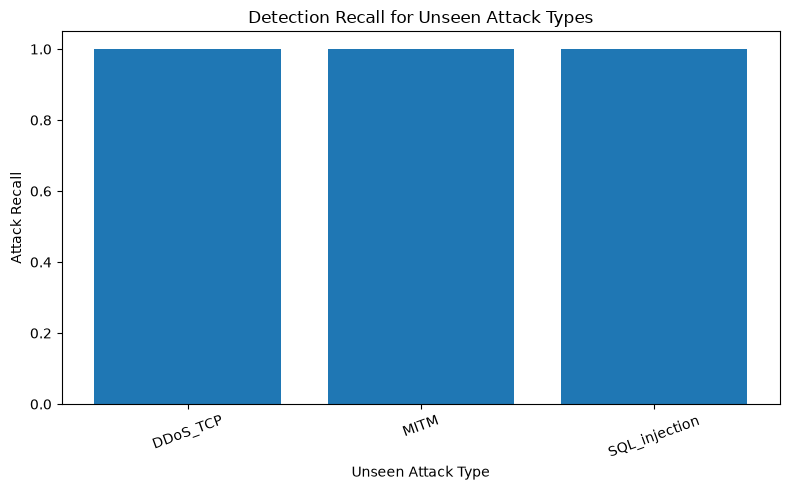

In [133]:
import matplotlib.pyplot as plt

plot_data = type_results[
    type_results["Attack Type"] != "Normal"
].copy()

plt.figure(figsize=(8, 5))

plt.bar(
    plot_data["Attack Type"],
    plot_data["Recall"]
)

plt.ylim(0, 1.05)
plt.xlabel("Unseen Attack Type")
plt.ylabel("Attack Recall")
plt.title("Detection Recall for Unseen Attack Types")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

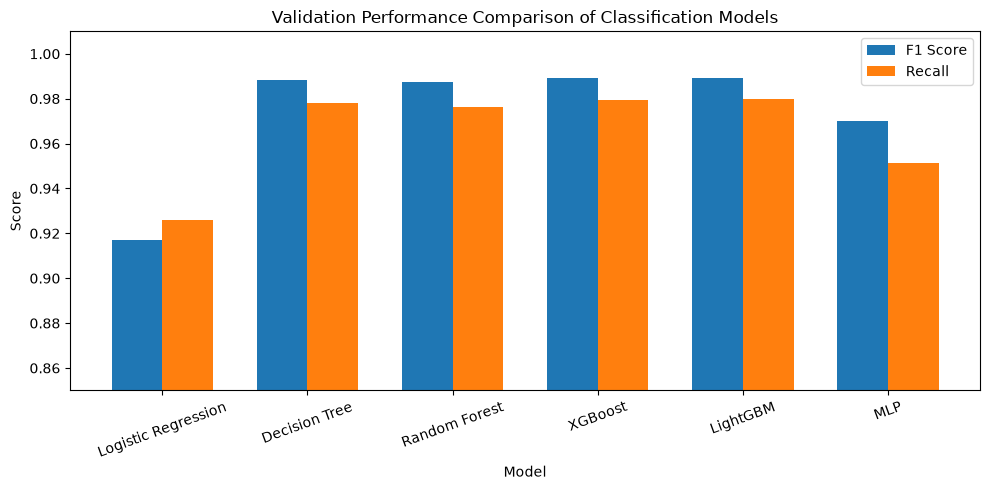

In [134]:
# Dataset 2 - Model Comparison

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "MLP"
]

f1_scores = [
    0.9170214291,
    0.9883127331,
    0.9872628250,
    0.9890087404,
    0.9891140757,
    0.9698946312
]

recall_scores = [
    0.9261414633,
    0.9781116998,
    0.9762008165,
    0.9795593387,
    0.9799357248,
    0.9514172385
]

plt.figure(figsize=(10, 5))

x = np.arange(len(models))
width = 0.35

plt.bar(
    x - width/2,
    f1_scores,
    width,
    label="F1 Score"
)

plt.bar(
    x + width/2,
    recall_scores,
    width,
    label="Recall"
)

plt.xticks(x, models, rotation=20)
plt.ylim(0.85, 1.01)

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Validation Performance Comparison of Classification Models")
plt.legend()

plt.tight_layout()
plt.show()

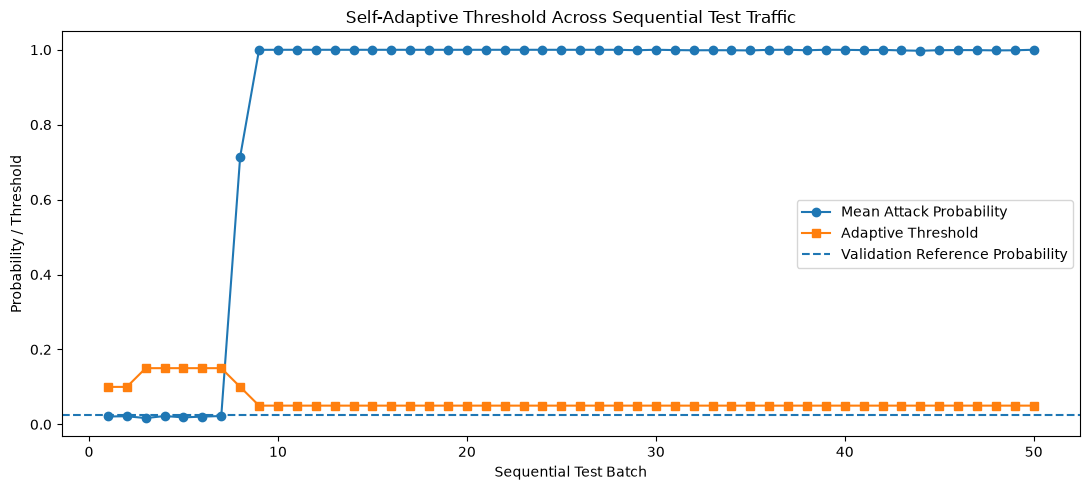

In [135]:
# Dataset 2 - Self-Adaptive Threshold Across Sequential Test Batches

batches_num = [b["batch"] for b in test_batches]
mean_probs = [b["mean_prob"] for b in test_batches]

plt.figure(figsize=(11, 5))

plt.plot(
    batches_num,
    mean_probs,
    marker="o",
    label="Mean Attack Probability"
)

plt.plot(
    batches_num,
    test_thresholds,
    marker="s",
    label="Adaptive Threshold"
)

plt.axhline(
    ref_prob,
    linestyle="--",
    label="Validation Reference Probability"
)

plt.xlabel("Sequential Test Batch")
plt.ylabel("Probability / Threshold")
plt.title("Self-Adaptive Threshold Across Sequential Test Traffic")
plt.legend()

plt.tight_layout()
plt.show()

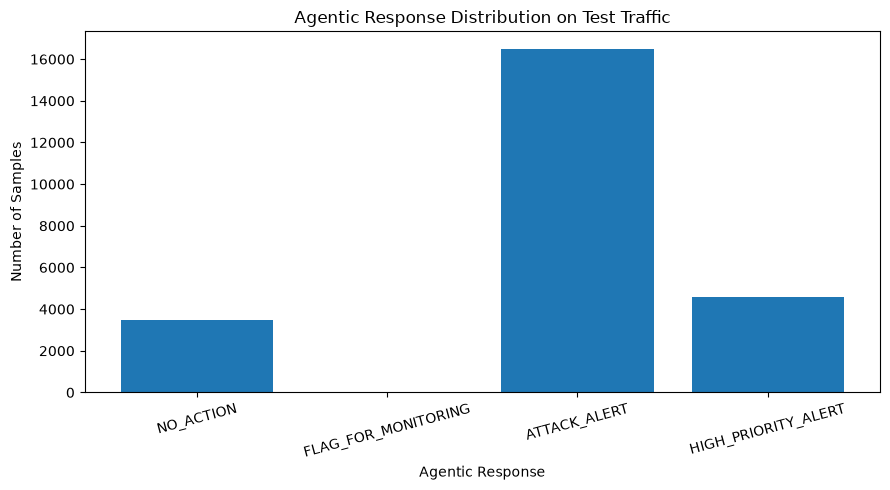

In [136]:
# Dataset 2 - Agentic Response Distribution

response_counts = pd.Series(test_responses).value_counts()

response_order = [
    "NO_ACTION",
    "FLAG_FOR_MONITORING",
    "ATTACK_ALERT",
    "HIGH_PRIORITY_ALERT"
]

response_counts = response_counts.reindex(
    response_order,
    fill_value=0
)

plt.figure(figsize=(9, 5))

plt.bar(
    response_counts.index,
    response_counts.values
)

plt.xlabel("Agentic Response")
plt.ylabel("Number of Samples")
plt.title("Agentic Response Distribution on Test Traffic")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [137]:
# Dataset 2 - Agentic Operational Metrics

# Convert agentic decisions into operational binary predictions
# Attack = 1
# Suspicious = also treated as requiring attention
# Normal = 0

y_test_agentic = np.where(
    test_decisions == "Normal",
    0,
    1
)

# Calculate metrics
agent_acc = accuracy_score(y_test_g, y_test_agentic)
agent_prec = precision_score(y_test_g, y_test_agentic)
agent_rec = recall_score(y_test_g, y_test_agentic)
agent_f1 = f1_score(y_test_g, y_test_agentic)

agent_cm = confusion_matrix(y_test_g, y_test_agentic)

tn_a, fp_a, fn_a, tp_a = agent_cm.ravel()

agent_fpr = fp_a / (fp_a + tn_a)
agent_fnr = fn_a / (fn_a + tp_a)

print("AGENTIC OPERATIONAL PERFORMANCE")
print("--------------------------------")
print(f"Accuracy   : {agent_acc:.4f}")
print(f"Precision  : {agent_prec:.4f}")
print(f"Recall     : {agent_rec:.4f}")
print(f"F1 Score   : {agent_f1:.4f}")
print(f"FPR        : {agent_fpr:.4f}")
print(f"FNR        : {agent_fnr:.4f}")

print("\nConfusion Matrix:")
print(agent_cm)

print("\nCounts:")
print(f"TN = {tn_a}")
print(f"FP = {fp_a}")
print(f"FN = {fn_a}")
print(f"TP = {tp_a}")

AGENTIC OPERATIONAL PERFORMANCE
--------------------------------
Accuracy   : 0.9928
Precision  : 0.9916
Recall     : 1.0000
F1 Score   : 0.9958
FPR        : 0.0488
FNR        : 0.0000

Confusion Matrix:
[[ 3468   178]
 [    0 20958]]

Counts:
TN = 3468
FP = 178
FN = 0
TP = 20958


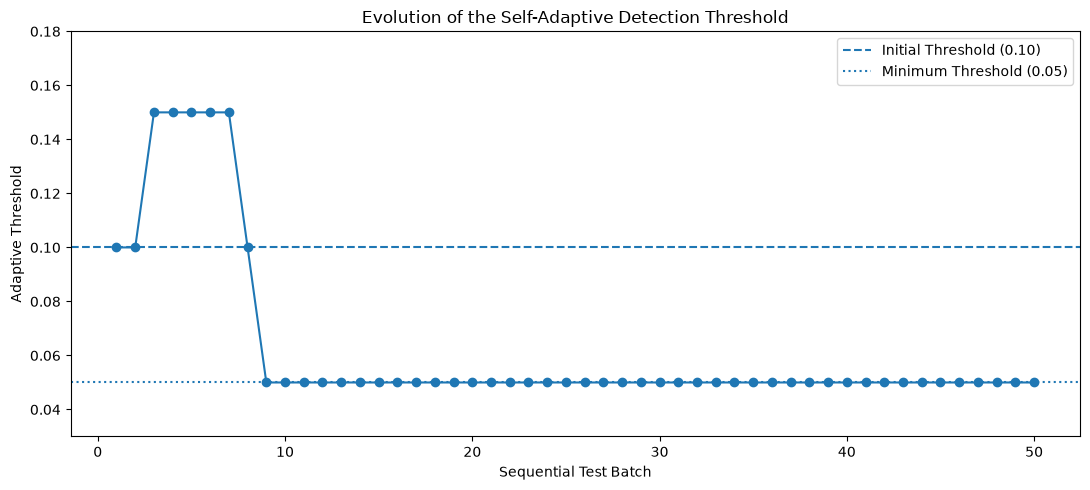

In [138]:
# Dataset 2 - Adaptive Threshold Evolution

plt.figure(figsize=(11, 5))

plt.plot(
    batches_num,
    test_thresholds,
    marker="o"
)

plt.axhline(
    base_threshold,
    linestyle="--",
    label="Initial Threshold (0.10)"
)

plt.axhline(
    lower_limit,
    linestyle=":",
    label="Minimum Threshold (0.05)"
)

plt.xlabel("Sequential Test Batch")
plt.ylabel("Adaptive Threshold")
plt.title("Evolution of the Self-Adaptive Detection Threshold")
plt.ylim(0.03, 0.18)
plt.legend()

plt.tight_layout()
plt.show()

In [139]:
# Gradual self-adaptive threshold - validation experiment

grad_step = 0.01
grad_base_threshold = 0.10
grad_lower_limit = 0.05
grad_upper_limit = 0.30

grad_val_thresholds = []
current_grad_threshold = grad_base_threshold

for b in batches:
    current_prob = b["mean_prob"]

    if current_prob > ref_prob * 1.25:
        current_grad_threshold = max(
            grad_lower_limit,
            current_grad_threshold - grad_step
        )

    elif current_prob < ref_prob * 0.75:
        current_grad_threshold = min(
            grad_upper_limit,
            current_grad_threshold + grad_step
        )

    grad_val_thresholds.append(current_grad_threshold)


print("Validation Reference Probability:", ref_prob)
print("Initial Threshold:", grad_base_threshold)
print("Adaptation Step:", grad_step)

print("\nGradual Validation Thresholds:")

for i in range(len(batches)):
    print(
        f"Batch {batches[i]['batch']:2d} | "
        f"Mean Prob={batches[i]['mean_prob']:.4f} | "
        f"Threshold={grad_val_thresholds[i]:.2f}"
    )

Validation Reference Probability: 0.024390243
Initial Threshold: 0.1
Adaptation Step: 0.01

Gradual Validation Thresholds:
Batch  1 | Mean Prob=0.0244 | Threshold=0.10
Batch  2 | Mean Prob=0.0186 | Threshold=0.10
Batch  3 | Mean Prob=0.0296 | Threshold=0.10
Batch  4 | Mean Prob=0.0178 | Threshold=0.11
Batch  5 | Mean Prob=0.0188 | Threshold=0.11
Batch  6 | Mean Prob=0.0169 | Threshold=0.12
Batch  7 | Mean Prob=0.0126 | Threshold=0.13
Batch  8 | Mean Prob=0.7153 | Threshold=0.12
Batch  9 | Mean Prob=0.9999 | Threshold=0.11
Batch 10 | Mean Prob=0.9718 | Threshold=0.10
Batch 11 | Mean Prob=0.9308 | Threshold=0.09
Batch 12 | Mean Prob=0.9998 | Threshold=0.08
Batch 13 | Mean Prob=0.9592 | Threshold=0.07
Batch 14 | Mean Prob=0.9440 | Threshold=0.06
Batch 15 | Mean Prob=0.9998 | Threshold=0.05
Batch 16 | Mean Prob=0.9588 | Threshold=0.05
Batch 17 | Mean Prob=0.9492 | Threshold=0.05
Batch 18 | Mean Prob=0.9998 | Threshold=0.05
Batch 19 | Mean Prob=0.9020 | Threshold=0.05
Batch 20 | Mean Prob=0

In [140]:
# Evaluate gradual adaptive threshold on validation data

y_val_pred_gradual = np.zeros(len(y_val_prob), dtype=int)

start = 0

for i, b in enumerate(batches):
    end = start + b["size"]
    threshold = grad_val_thresholds[i]

    y_val_pred_gradual[start:end] = (
        y_val_prob[start:end] >= threshold
    ).astype(int)

    start = end


# Calculate metrics
grad_acc = accuracy_score(y_val_g, y_val_pred_gradual)
grad_prec = precision_score(y_val_g, y_val_pred_gradual)
grad_rec = recall_score(y_val_g, y_val_pred_gradual)
grad_f1 = f1_score(y_val_g, y_val_pred_gradual)

grad_cm = confusion_matrix(y_val_g, y_val_pred_gradual)

tn_g, fp_g, fn_g, tp_g = grad_cm.ravel()

grad_fpr = fp_g / (fp_g + tn_g)
grad_fnr = fn_g / (fn_g + tp_g)

print("GRADUAL ADAPTIVE VALIDATION PERFORMANCE")
print("----------------------------------------")
print(f"Accuracy   : {grad_acc:.4f}")
print(f"Precision  : {grad_prec:.4f}")
print(f"Recall     : {grad_rec:.4f}")
print(f"F1 Score   : {grad_f1:.4f}")
print(f"FPR        : {grad_fpr:.4f}")
print(f"FNR        : {grad_fnr:.4f}")

print("\nConfusion Matrix:")
print(grad_cm)

print("\nCounts:")
print(f"TN = {tn_g}")
print(f"FP = {fp_g}")
print(f"FN = {fn_g}")
print(f"TP = {tp_g}")

GRADUAL ADAPTIVE VALIDATION PERFORMANCE
----------------------------------------
Accuracy   : 0.9918
Precision  : 0.9956
Recall     : 0.9953
F1 Score   : 0.9954
FPR        : 0.0417
FNR        : 0.0047

Confusion Matrix:
[[ 3493   152]
 [  163 34376]]

Counts:
TN = 3493
FP = 152
FN = 163
TP = 34376


In [141]:
# Apply frozen gradual adaptive rule to test data

test_grad_thresholds = []
current_grad_test_threshold = grad_base_threshold

for b in test_batches:
    current_prob = b["mean_prob"]

    if current_prob > ref_prob * 1.25:
        current_grad_test_threshold = max(
            grad_lower_limit,
            current_grad_test_threshold - grad_step
        )

    elif current_prob < ref_prob * 0.75:
        current_grad_test_threshold = min(
            grad_upper_limit,
            current_grad_test_threshold + grad_step
        )

    test_grad_thresholds.append(current_grad_test_threshold)


print("Validation Reference Probability:", ref_prob)
print("Initial Threshold:", grad_base_threshold)
print("Adaptation Step:", grad_step)

print("\nGradual Adaptive Test Thresholds:")

for i in range(len(test_batches)):
    print(
        f"Batch {test_batches[i]['batch']:2d} | "
        f"Mean Prob={test_batches[i]['mean_prob']:.4f} | "
        f"Threshold={test_grad_thresholds[i]:.2f}"
    )

Validation Reference Probability: 0.024390243
Initial Threshold: 0.1
Adaptation Step: 0.01

Gradual Adaptive Test Thresholds:
Batch  1 | Mean Prob=0.0210 | Threshold=0.10
Batch  2 | Mean Prob=0.0217 | Threshold=0.10
Batch  3 | Mean Prob=0.0168 | Threshold=0.11
Batch  4 | Mean Prob=0.0222 | Threshold=0.11
Batch  5 | Mean Prob=0.0186 | Threshold=0.11
Batch  6 | Mean Prob=0.0207 | Threshold=0.11
Batch  7 | Mean Prob=0.0223 | Threshold=0.11
Batch  8 | Mean Prob=0.7146 | Threshold=0.10
Batch  9 | Mean Prob=0.9998 | Threshold=0.09
Batch 10 | Mean Prob=0.9999 | Threshold=0.08
Batch 11 | Mean Prob=0.9999 | Threshold=0.07
Batch 12 | Mean Prob=0.9999 | Threshold=0.06
Batch 13 | Mean Prob=0.9999 | Threshold=0.05
Batch 14 | Mean Prob=0.9998 | Threshold=0.05
Batch 15 | Mean Prob=0.9999 | Threshold=0.05
Batch 16 | Mean Prob=0.9999 | Threshold=0.05
Batch 17 | Mean Prob=0.9999 | Threshold=0.05
Batch 18 | Mean Prob=0.9999 | Threshold=0.05
Batch 19 | Mean Prob=0.9999 | Threshold=0.05
Batch 20 | Mean Pro

In [142]:
# Gradual adaptive predictions on test data

y_test_pred_gradual = np.zeros(len(y_test_prob), dtype=int)

start = 0

for i, b in enumerate(test_batches):
    end = start + b["size"]
    threshold = test_grad_thresholds[i]

    y_test_pred_gradual[start:end] = (
        y_test_prob[start:end] >= threshold
    ).astype(int)

    start = end


# Calculate metrics
grad_test_acc = accuracy_score(
    y_test_g,
    y_test_pred_gradual
)

grad_test_prec = precision_score(
    y_test_g,
    y_test_pred_gradual
)

grad_test_rec = recall_score(
    y_test_g,
    y_test_pred_gradual
)

grad_test_f1 = f1_score(
    y_test_g,
    y_test_pred_gradual
)

grad_test_roc = roc_auc_score(
    y_test_g,
    y_test_prob
)

grad_test_pr = average_precision_score(
    y_test_g,
    y_test_prob
)

grad_test_cm = confusion_matrix(
    y_test_g,
    y_test_pred_gradual
)

tn, fp, fn, tp = grad_test_cm.ravel()

grad_test_fpr = fp / (fp + tn)
grad_test_fnr = fn / (fn + tp)


print("FINAL GRADUAL ADAPTIVE TEST PERFORMANCE")
print("----------------------------------------")
print(f"Accuracy   : {grad_test_acc:.4f}")
print(f"Precision  : {grad_test_prec:.4f}")
print(f"Recall     : {grad_test_rec:.4f}")
print(f"F1 Score   : {grad_test_f1:.4f}")
print(f"ROC-AUC    : {grad_test_roc:.4f}")
print(f"PR-AUC     : {grad_test_pr:.4f}")
print(f"FPR        : {grad_test_fpr:.4f}")
print(f"FNR        : {grad_test_fnr:.4f}")

print("\nConfusion Matrix:")
print(grad_test_cm)

print("\nCounts:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

FINAL GRADUAL ADAPTIVE TEST PERFORMANCE
----------------------------------------
Accuracy   : 0.9935
Precision  : 0.9924
Recall     : 1.0000
F1 Score   : 0.9962
ROC-AUC    : 0.9999
PR-AUC     : 1.0000
FPR        : 0.0439
FNR        : 0.0000

Confusion Matrix:
[[ 3486   160]
 [    0 20958]]

Counts:
TN = 3486
FP = 160
FN = 0
TP = 20958


In [143]:
# Final Agentic Layer using Gradual Adaptive Thresholds

test_decisions_gradual = []
test_responses_gradual = []

for i, b in enumerate(test_batches):

    start = sum(x["size"] for x in test_batches[:i])
    end = start + b["size"]

    threshold = test_grad_thresholds[i]

    for j in range(start, end):

        decision = detection_agent(
            y_test_prob[j],
            threshold
        )

        response = response_agent(
            decision,
            y_test_prob[j]
        )

        test_decisions_gradual.append(decision)
        test_responses_gradual.append(response)


test_decisions_gradual = np.array(test_decisions_gradual)
test_responses_gradual = np.array(test_responses_gradual)


print("FINAL GRADUAL AGENTIC DECISION DISTRIBUTION")
print("--------------------------------------------")

unique_dec, counts_dec = np.unique(
    test_decisions_gradual,
    return_counts=True
)

for d, c in zip(unique_dec, counts_dec):
    print(f"{d}: {c}")


print("\nFINAL GRADUAL AGENTIC RESPONSE DISTRIBUTION")
print("--------------------------------------------")

unique_resp, counts_resp = np.unique(
    test_responses_gradual,
    return_counts=True
)

for r, c in zip(unique_resp, counts_resp):
    print(f"{r}: {c}")

FINAL GRADUAL AGENTIC DECISION DISTRIBUTION
--------------------------------------------
Attack: 21118
Normal: 3458
Suspicious: 28

FINAL GRADUAL AGENTIC RESPONSE DISTRIBUTION
--------------------------------------------
ATTACK_ALERT: 16519
FLAG_FOR_MONITORING: 28
HIGH_PRIORITY_ALERT: 4599
NO_ACTION: 3458


In [144]:
# Final Gradual Adaptive Agentic Metrics

# Treat both Attack and Suspicious as requiring attention
y_test_agent_pred = np.isin(
    test_decisions_gradual,
    ["Attack", "Suspicious"]
).astype(int)

agent_acc = accuracy_score(
    y_test_g,
    y_test_agent_pred
)

agent_prec = precision_score(
    y_test_g,
    y_test_agent_pred
)

agent_rec = recall_score(
    y_test_g,
    y_test_agent_pred
)

agent_f1 = f1_score(
    y_test_g,
    y_test_agent_pred
)

agent_cm = confusion_matrix(
    y_test_g,
    y_test_agent_pred
)

tn, fp, fn, tp = agent_cm.ravel()

agent_fpr = fp / (fp + tn)
agent_fnr = fn / (fn + tp)

print("FINAL GRADUAL ADAPTIVE AGENTIC PERFORMANCE")
print("--------------------------------------------")
print(f"Accuracy   : {agent_acc:.4f}")
print(f"Precision  : {agent_prec:.4f}")
print(f"Recall     : {agent_rec:.4f}")
print(f"F1 Score   : {agent_f1:.4f}")
print(f"FPR        : {agent_fpr:.4f}")
print(f"FNR        : {agent_fnr:.4f}")

print("\nConfusion Matrix:")
print(agent_cm)

print("\nCounts:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

FINAL GRADUAL ADAPTIVE AGENTIC PERFORMANCE
--------------------------------------------
Accuracy   : 0.9924
Precision  : 0.9911
Recall     : 1.0000
F1 Score   : 0.9955
FPR        : 0.0516
FNR        : 0.0000

Confusion Matrix:
[[ 3458   188]
 [    0 20958]]

Counts:
TN = 3458
FP = 188
FN = 0
TP = 20958


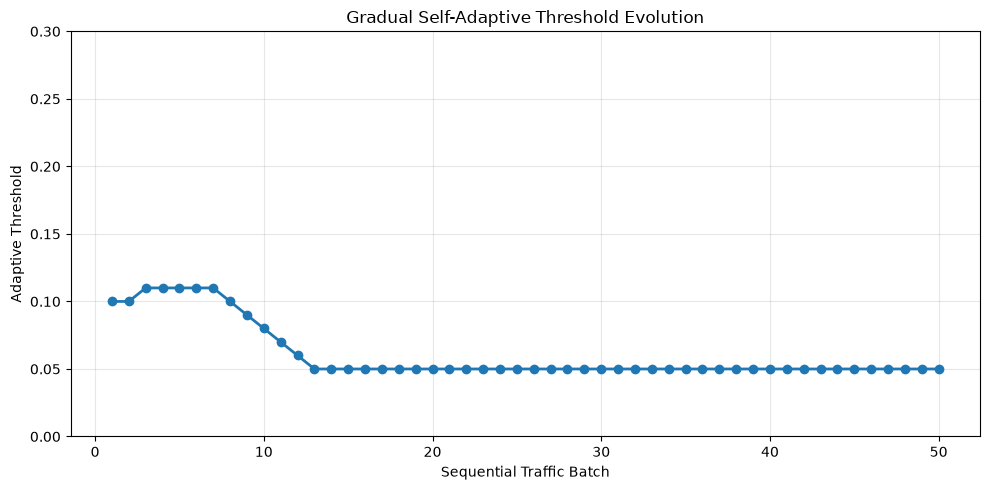

In [145]:
import matplotlib.pyplot as plt

# Batch numbers
batches_num = range(1, len(test_grad_thresholds) + 1)

# Plot gradual adaptive threshold
plt.figure(figsize=(10, 5))

plt.plot(
    batches_num,
    test_grad_thresholds,
    marker="o",
    linewidth=2
)

plt.xlabel("Sequential Traffic Batch")
plt.ylabel("Adaptive Threshold")
plt.title("Gradual Self-Adaptive Threshold Evolution")

plt.ylim(0, 0.30)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

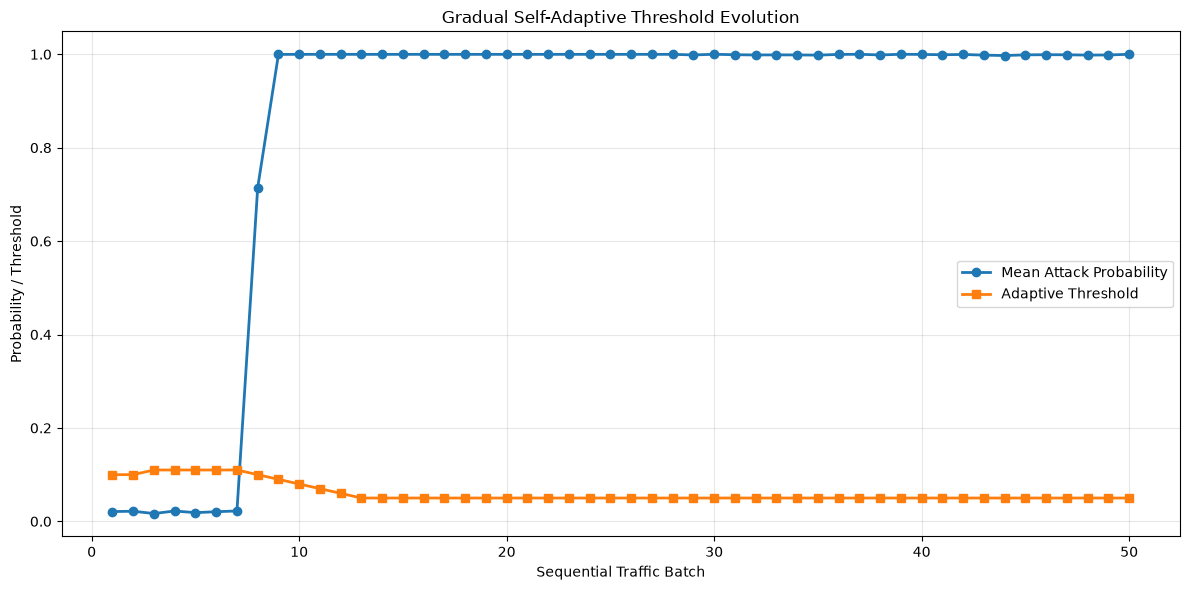

In [146]:
import matplotlib.pyplot as plt

batches_num = range(1, len(test_batches) + 1)

mean_probs = [
    b["mean_prob"]
    for b in test_batches
]

thresholds = test_grad_thresholds

plt.figure(figsize=(12, 6))

plt.plot(
    batches_num,
    mean_probs,
    marker="o",
    linewidth=2,
    label="Mean Attack Probability"
)

plt.plot(
    batches_num,
    thresholds,
    marker="s",
    linewidth=2,
    label="Adaptive Threshold"
)

plt.xlabel("Sequential Traffic Batch")
plt.ylabel("Probability / Threshold")
plt.title("Gradual Self-Adaptive Threshold Evolution")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [1]:

from pathlib import Path

# Run this script from your project root directory.
project_dir = Path.cwd()
experiments_dir = project_dir / "experiments"
experiments_dir.mkdir(parents=True, exist_ok=True)

files = {
    experiments_dir / "ABLATION_STUDY.md": r"""# XGBoost Ablation Study

## Objective
Evaluate the contribution of selected features and feature groups
to the Edge-IIoTset intrusion detection model.

## Dataset
- Dataset: Edge-IIoTset
- Model: XGBoost
- Features: 12 network/transport-level behavioral features
- Evaluation: Scenario-aware validation split

## Experiments
1. Full model with all 12 features.
2. Without tcp.dstport.
3. Without tcp.ack.
4. Without tcp.flags.
5. Without tcp.len.
6. Without selected TCP connection-flag features.
7. Without UDP features.
8. Without the DNS feature.

## Metrics
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Average Precision (AP)

## Method
For each configuration, remove the specified features, train an
XGBoost classifier using the same hyperparameters, and evaluate it
on the same validation split. Compare each result with the full
12-feature baseline.

## Reproducibility
Random seed: 42.

The training and validation data must be generated using the
project's documented preprocessing and scenario-aware splitting
procedure.

## Results
The measured results will be saved to:
`ablation_study_validation_results.csv`

Only report results produced by successfully executed experiments.
""",

    experiments_dir / "ablation_study.py": r'''"""
XGBoost ablation study for Edge-IIoTset.

Prerequisites:
Prepare X_train_g, X_val_g, y_train_g, and y_val_g using the
project's existing preprocessing and scenario-aware split pipeline.

Run this script in an environment where those variables are loaded,
or integrate this code into the notebook that creates them.
"""

import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

FEATURES = [
    "tcp.ack",
    "tcp.connection.fin",
    "tcp.connection.rst",
    "tcp.connection.syn",
    "tcp.connection.synack",
    "tcp.dstport",
    "tcp.flags",
    "tcp.flags.ack",
    "tcp.len",
    "udp.port",
    "udp.time_delta",
    "dns.qry.qu",
]

ABLATIONS = {
    "Full model (12 features)": [],
    "Without tcp.dstport": ["tcp.dstport"],
    "Without tcp.ack": ["tcp.ack"],
    "Without tcp.flags": ["tcp.flags"],
    "Without tcp.len": ["tcp.len"],
    "Without TCP connection flags": [
        "tcp.connection.fin",
        "tcp.connection.rst",
        "tcp.connection.syn",
        "tcp.connection.synack",
        "tcp.flags.ack",
    ],
    "Without UDP features": ["udp.port", "udp.time_delta"],
    "Without DNS feature": ["dns.qry.qu"],
}


def run_ablation_study(
    X_train_g, y_train_g, X_val_g, y_val_g
):
    """Train each ablation model and return validation metrics."""
    missing = set(FEATURES) - set(X_train_g.columns)
    missing |= set(FEATURES) - set(X_val_g.columns)
    if missing:
        raise ValueError(f"Missing required features: {sorted(missing)}")

    results = []

    for experiment, removed in ABLATIONS.items():
        remaining = [f for f in FEATURES if f not in removed]

        clf = XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric="logloss",
        )

        clf.fit(X_train_g[remaining], y_train_g)

        predictions = clf.predict(X_val_g[remaining])
        probabilities = clf.predict_proba(X_val_g[remaining])[:, 1]

        results.append({
            "Experiment": experiment,
            "Features Used": len(remaining),
            "Accuracy": accuracy_score(y_val_g, predictions),
            "Precision": precision_score(
                y_val_g, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val_g, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val_g, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_val_g, probabilities),
            "Average Precision": average_precision_score(
                y_val_g, probabilities
            ),
        })

    results_df = pd.DataFrame(results)
    output_path = "ablation_study_validation_results.csv"
    results_df.to_csv(output_path, index=False)

    print(results_df.round(5).to_string(index=False))
    print(f"\nSaved results to: {output_path}")
    return results_df


# This file deliberately does not load or split the dataset automatically.
# Call run_ablation_study(...) after loading your verified split variables.
''',

    project_dir / "requirements-ablation.txt": """pandas
scikit-learn
xgboost
""",
}

for path, content in files.items():
    if path.exists():
        print(f"Kept existing file (not overwritten): {path}")
        continue

    path.write_text(content, encoding="utf-8")
    print(f"Created: {path}")

print("\nDone. Review the generated files before committing them.")


Created: c:\Users\shyam\edge_model\Edge-iiot\experiments\ABLATION_STUDY.md
Created: c:\Users\shyam\edge_model\Edge-iiot\experiments\ablation_study.py
Created: c:\Users\shyam\edge_model\Edge-iiot\requirements-ablation.txt

Done. Review the generated files before committing them.
